<a href="https://colab.research.google.com/github/aniket-s9/Car_Price_Predictor/blob/main/complete_ml_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction & Segmentation — Complete ML Project

## Project Introduction & Problem Statement
Customer churn (subscribers canceling service) directly impacts recurring revenue in telecom businesses. Using historical customer demographics, subscribed services, contract details, and billing records, our goal is to:
1. Understand key churn drivers through **Exploratory Data Analysis (EDA)**.
2. Segment customers without labels using **K-Means** and **DBSCAN**.
3. Identify the most informative predictors using **Filter**, **Wrapper (RFE)**, and **Embedded** feature selection.
4. Compress correlated features using **Principal Component Analysis (PCA)**.
5. Predict customer churn reliably using **Scikit-learn Pipelines**, **Stratified 5-Fold Cross-Validation**, and **Bagging, Boosting, and Stacking** ensembles.

### Allowed Libraries & Algorithms
- **Libraries:** Python, Scikit-learn (primary ML toolkit), Pandas & NumPy (data handling/arrays where needed), Matplotlib & Seaborn (visualization).
- **Algorithms Used (Strictly 10):**
  1. K-Means (`KMeans`)
  2. DBSCAN (`DBSCAN`)
  3. Filter Feature Selection (`SelectKBest` with `f_classif`)
  4. Wrapper Feature Selection (`RFE`)
  5. Embedded Feature Selection (`SelectFromModel` with L1 `LogisticRegression`)
  6. PCA (`PCA`)
  7. Stratified K-Fold (`StratifiedKFold` + `cross_validate`)
  8. Bagging (`BaggingClassifier`)
  9. Boosting (`GradientBoostingClassifier`)
  10. Stacking (`StackingClassifier`)
- **Minimal Base Estimators:** Only `LogisticRegression` (linear classifier, RFE/L1 selector, Stacking meta-learner) and `DecisionTreeClassifier` (single-tree baseline & Bagging base learner) are used.

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Preprocessing, Splitting & Pipelines
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
)

# Scikit-learn: Unsupervised Learning & Dimensionality Reduction
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA

# Scikit-learn: Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel

# Scikit-learn: Base Estimators & Ensembles
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

# Scikit-learn: Evaluation Metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

# Reproducibility and plotting style
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

# Locate dataset cleanly whether run locally (notebooks/ or root) or uploaded to Google Colab (/content)
candidate_paths = [
    "../dataset/dataset.csv",
    "dataset/dataset.csv",
    "dataset.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
DATASET_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Upload dataset.csv (or WA_Fn-UseC_-Telco-Customer-Churn.csv) to the current folder."
    )

abs_dataset = os.path.abspath(DATASET_PATH)
dataset_parent = os.path.dirname(abs_dataset)
PROJECT_DIR = os.path.dirname(dataset_parent) if os.path.basename(dataset_parent) == "dataset" else dataset_parent
VIS_DIR = os.path.join(PROJECT_DIR, "results", "visualizations")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(VIS_DIR, exist_ok=True)

# Compatibility for L1 penalty between Colab (sklearn <=1.7) and sklearn >=1.8
import sklearn
_sk_ver = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
L1_KWARGS = {"l1_ratio": 1.0} if _sk_ver >= (1, 8) else {"penalty": "l1"}

print("Using dataset:", abs_dataset)
print("Saving visualizations to:", VIS_DIR)

Using dataset: /Users/aniketsingh/Proj-ML/machine_learning_project/dataset/dataset.csv
Saving visualizations to: /Users/aniketsingh/Proj-ML/machine_learning_project/results/visualizations


## 1. Dataset Loading, Requirement Check & Feature Explanation

First, we load the dataset and check the required constraints:
- Minimum **5,000 samples (rows)**
- Minimum **10 features (columns)**
- Clear numerical and categorical features
- Well-defined supervised target variable (`Churn`)

In [ ]:
raw_df = pd.read_csv(DATASET_PATH)

print(f"Dataset Shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print("Meets >= 5,000 rows requirement   :", raw_df.shape[0] >= 5000)
print("Meets >= 10 columns requirement :", raw_df.shape[1] >= 10)

display(raw_df.head())

Dataset Shape: 7,043 rows x 21 columns
Meets >= 5,000 rows requirement   : True
Meets >= 10 columns requirement : True


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Inspect column types and document every feature in the dataset
print("=== Dataset Info ===")
raw_df.info()

feature_descriptions = {
    "customerID": "Unique customer ID (identifier; dropped before training)",
    "gender": "Customer gender (Female / Male)",
    "SeniorCitizen": "Whether customer is a senior citizen (0 = No, 1 = Yes)",
    "Partner": "Whether customer has a partner (Yes / No)",
    "Dependents": "Whether customer has dependents (Yes / No)",
    "tenure": "Months the customer has stayed with the company (Numerical)",
    "PhoneService": "Whether customer has phone service (Yes / No)",
    "MultipleLines": "Multiple phone lines (Yes / No / No phone service)",
    "InternetService": "Internet provider type (DSL / Fiber optic / No)",
    "OnlineSecurity": "Online security add-on (Yes / No / No internet service)",
    "OnlineBackup": "Online backup add-on (Yes / No / No internet service)",
    "DeviceProtection": "Device protection add-on (Yes / No / No internet service)",
    "TechSupport": "Tech support add-on (Yes / No / No internet service)",
    "StreamingTV": "Streaming TV add-on (Yes / No / No internet service)",
    "StreamingMovies": "Streaming movies add-on (Yes / No / No internet service)",
    "Contract": "Contract term (Month-to-month / One year / Two year)",
    "PaperlessBilling": "Paperless billing enabled (Yes / No)",
    "PaymentMethod": "Payment method (Electronic check, Mailed check, Bank transfer, Credit card)",
    "MonthlyCharges": "Monthly bill amount in USD (Numerical)",
    "TotalCharges": "Cumulative bill amount in USD (Numerical; stored as string with 11 blanks)",
    "Churn": "Target variable: customer left in the last month (Yes / No)",
}

feature_table = pd.DataFrame([
    {"Column": col, "Raw Dtype": str(raw_df[col].dtype), "Unique Values": raw_df[col].nunique(), "Description": desc}
    for col, desc in feature_descriptions.items()
])
display(feature_table)

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

,Column,Raw Dtype,Unique Values,Description
0,customerID,str,7043,Unique customer ID (identifier; dropped before...
1,gender,str,2,Customer gender (Female / Male)
2,SeniorCitizen,int64,2,"Whether customer is a senior citizen (0 = No, ..."
3,Partner,str,2,Whether customer has a partner (Yes / No)
4,Dependents,str,2,Whether customer has dependents (Yes / No)
5,tenure,int64,73,Months the customer has stayed with the compan...
6,PhoneService,str,2,Whether customer has phone service (Yes / No)
7,MultipleLines,str,3,Multiple phone lines (Yes / No / No phone serv...
8,InternetService,str,3,Internet provider type (DSL / Fiber optic / No)
9,OnlineSecurity,str,3,Online security add-on (Yes / No / No internet...


## 2. Exploratory Data Analysis (EDA)

In this section we examine:
- Statistical summaries for numerical and categorical features
- Missing values (including hidden whitespace in `TotalCharges`) and duplicate records
- Univariate distributions (histograms/KDE & count plots)
- Bivariate relationships with `Churn`
- Multivariate patterns, correlation matrix heatmap, and outlier boxplots

In [ ]:
# Create a working copy for EDA and fix TotalCharges data type
eda_df = raw_df.copy()
eda_df["TotalCharges"] = pd.to_numeric(eda_df["TotalCharges"].str.strip(), errors="coerce")
eda_df["SeniorCitizen"] = eda_df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print("=== Missing Values (Raw CSV vs After Numeric Parsing) ===")
print("Raw CSV NaNs   :", int(raw_df.isna().sum().sum()))
print("After Parsing  :", eda_df.isna().sum()[eda_df.isna().sum() > 0].to_dict())
print("Rows with missing TotalCharges:")
display(eda_df[eda_df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

print("\n=== Duplicate Check ===")
print("Exact duplicate rows   :", int(eda_df.duplicated().sum()))
print("Unique customer IDs    :", eda_df["customerID"].nunique(), "out of", len(eda_df))

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in eda_df.columns if c not in num_cols + ["customerID", "Churn"]]

print("\n=== Statistical Summary (Numerical Features) ===")
display(eda_df[num_cols].describe().round(2))

print("\n=== Statistical Summary (Categorical Features) ===")
display(eda_df[cat_cols + ["Churn"]].describe())

=== Missing Values (Raw CSV vs After Numeric Parsing) ===
Raw CSV NaNs   : 0
After Parsing  : {'TotalCharges': 11}
Rows with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No



=== Duplicate Check ===
Exact duplicate rows   : 0
Unique customer IDs    : 7043 out of 7043

=== Statistical Summary (Numerical Features) ===


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80



=== Statistical Summary (Categorical Features) ===


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


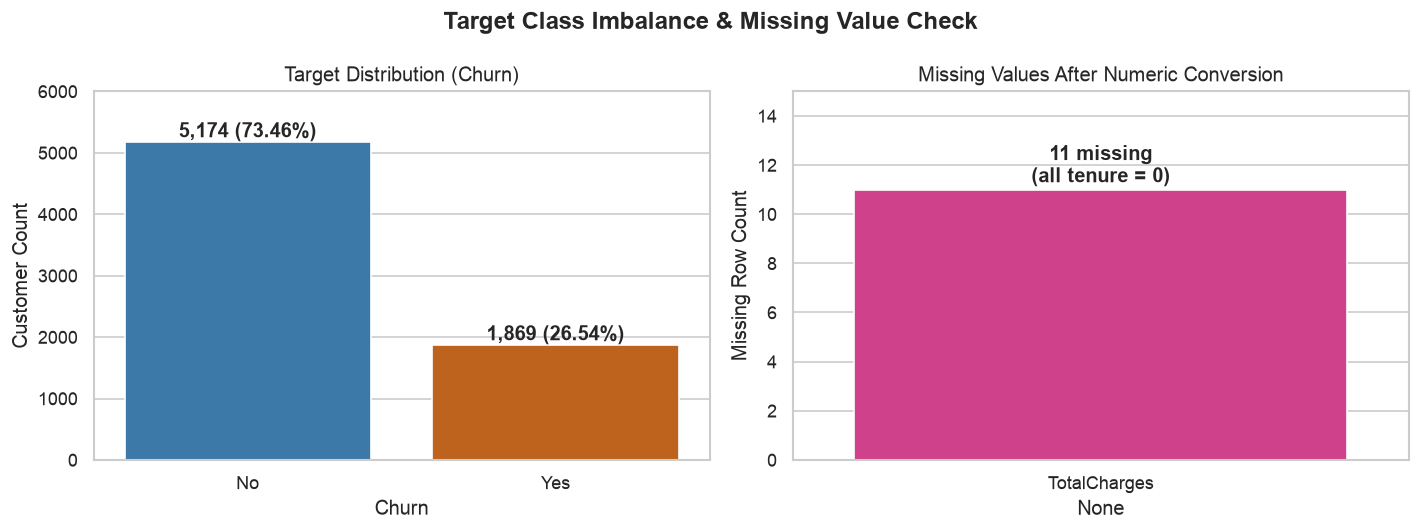

In [ ]:
# 1. Target Distribution & Missing Value Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

churn_counts = eda_df["Churn"].value_counts().reindex(["No", "Yes"])
sns.barplot(x=churn_counts.index, y=churn_counts.values, hue=churn_counts.index,
            palette={"No": "#2b7bba", "Yes": "#d95f02"}, legend=False, ax=axes[0])
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 80, f"{v:,} ({v/len(eda_df)*100:.2f}%)", ha="center", fontweight="bold")
axes[0].set_title("Target Distribution (Churn)")
axes[0].set_ylabel("Customer Count")
axes[0].set_ylim(0, churn_counts.max() * 1.16)

missing_counts = eda_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
sns.barplot(x=missing_counts.index, y=missing_counts.values, hue=missing_counts.index,
            palette=["#e7298a"], legend=False, ax=axes[1])
for i, v in enumerate(missing_counts.values):
    axes[1].text(i, v + 0.3, f"{v} missing\n(all tenure = 0)", ha="center", fontweight="bold")
axes[1].set_title("Missing Values After Numeric Conversion")
axes[1].set_ylabel("Missing Row Count")
axes[1].set_ylim(0, 15)

plt.suptitle("Target Class Imbalance & Missing Value Check", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "01_target_and_missing_analysis.png"), dpi=200, bbox_inches="tight")
plt.show()

**Observation:**
- The target variable `Churn` is moderately imbalanced (`73.46%` No vs `26.54%` Yes). Because a trivial baseline predicting all `No` gets `73.46%` accuracy, we must evaluate models using **Precision, Recall, and F1-Score** alongside Accuracy and use **Stratified** splits/folds.
- `TotalCharges` contains `11` hidden blank strings that become `NaN` when converted to numeric; all `11` belong to brand-new customers with `tenure == 0`.

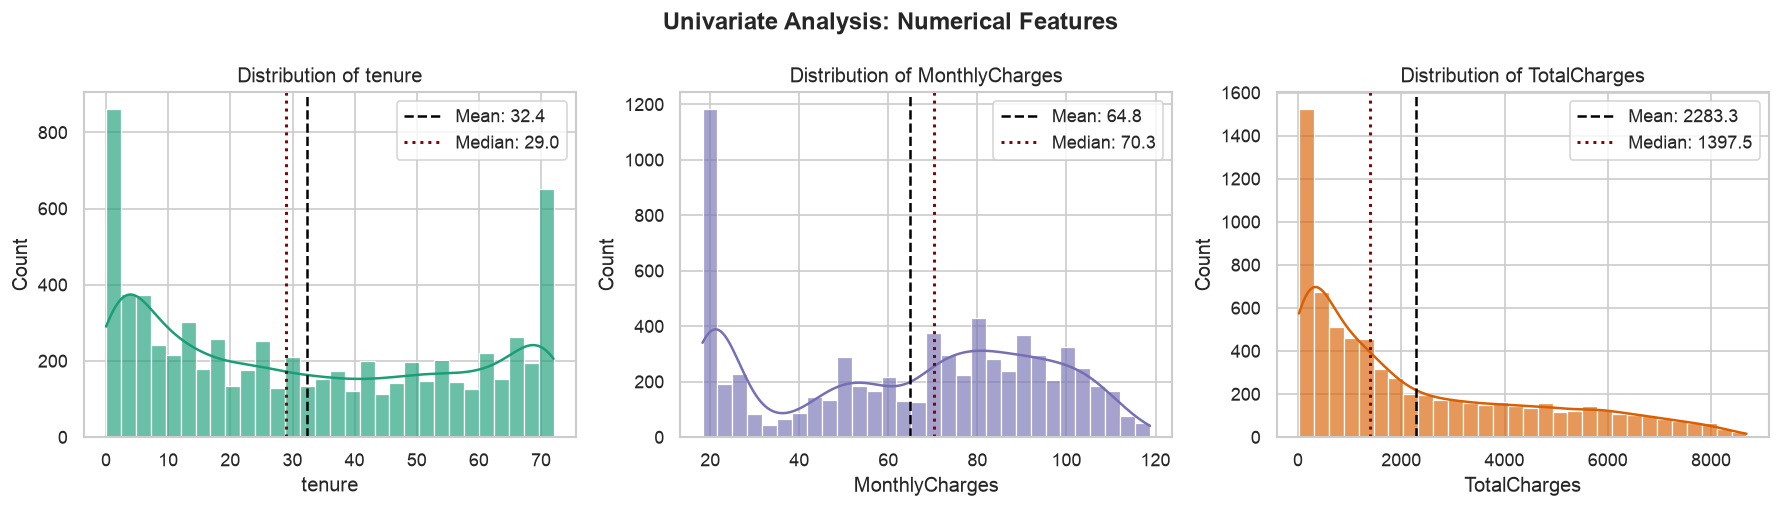

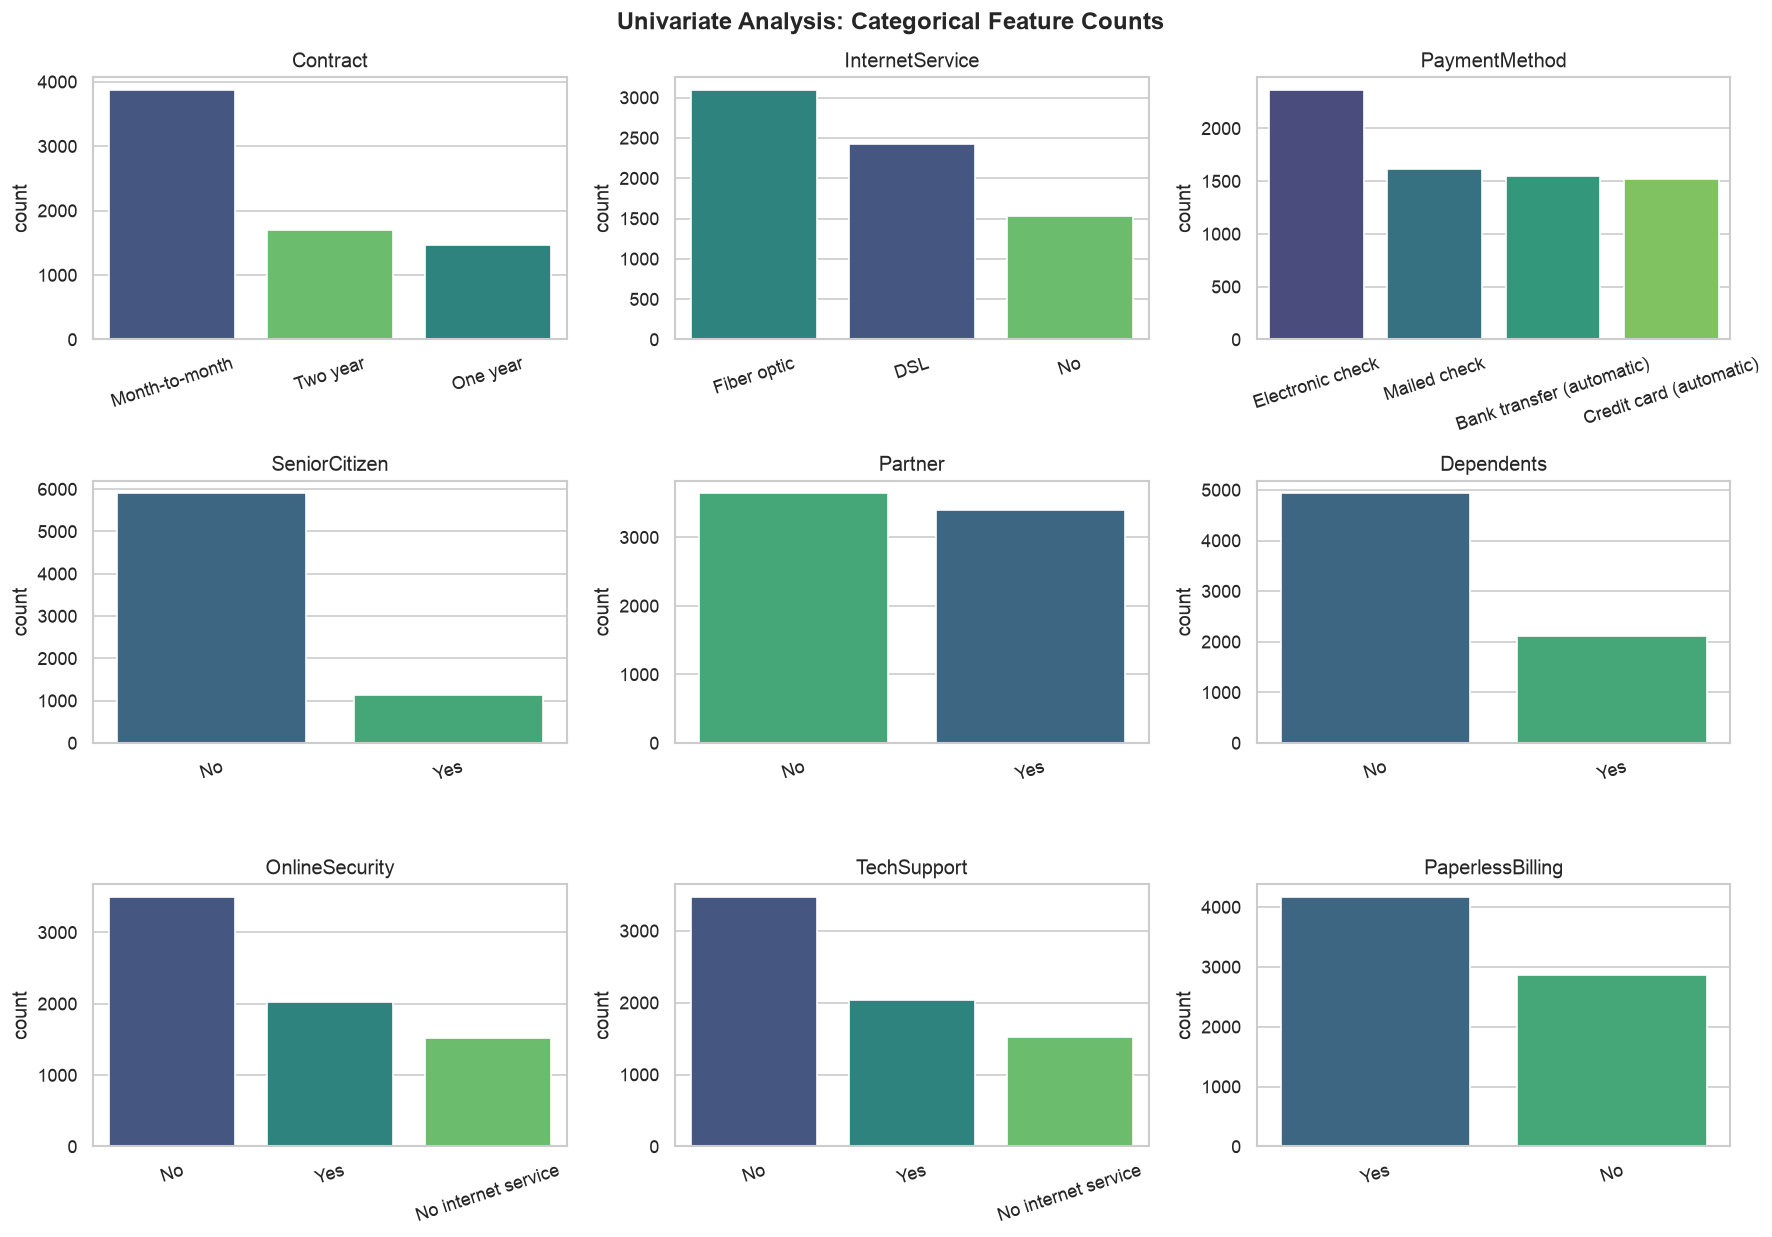

In [ ]:
# 2. Univariate Analysis: Numerical Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
colors = ["#1b9e77", "#7570b3", "#d95f02"]

for ax, col, color in zip(axes, num_cols, colors):
    vals = eda_df[col].dropna()
    sns.histplot(vals, kde=True, bins=30, color=color, alpha=0.65, ax=ax)
    ax.axvline(vals.mean(), color="black", linestyle="--", label=f"Mean: {vals.mean():.1f}")
    ax.axvline(vals.median(), color="darkred", linestyle=":", linewidth=1.8, label=f"Median: {vals.median():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.legend()

plt.suptitle("Univariate Analysis: Numerical Features", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "02_univariate_numerical_distributions.png"), dpi=200, bbox_inches="tight")
plt.show()

# 3. Univariate Analysis: Key Categorical Distributions
key_cats = ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen",
            "Partner", "Dependents", "OnlineSecurity", "TechSupport", "PaperlessBilling"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10.5))
for ax, col in zip(axes.ravel(), key_cats):
    order = eda_df[col].value_counts().index
    sns.countplot(data=eda_df, x=col, order=order, hue=col, palette="viridis", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=18)

plt.suptitle("Univariate Analysis: Categorical Feature Counts", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "03_univariate_categorical_distributions.png"), dpi=200, bbox_inches="tight")
plt.show()

**Observation:**
- `tenure` is bimodal (many brand-new 0–5 month customers and many loyal ~70-month customers). `TotalCharges` is right-skewed (`mean = $2,283.30`, `median = $1,397.47`) because charges accumulate over tenure.
- Over half of customers are on `Month-to-month` contracts (`3,875` customers), and `Fiber optic` is the most common internet tier (`3,096` customers).

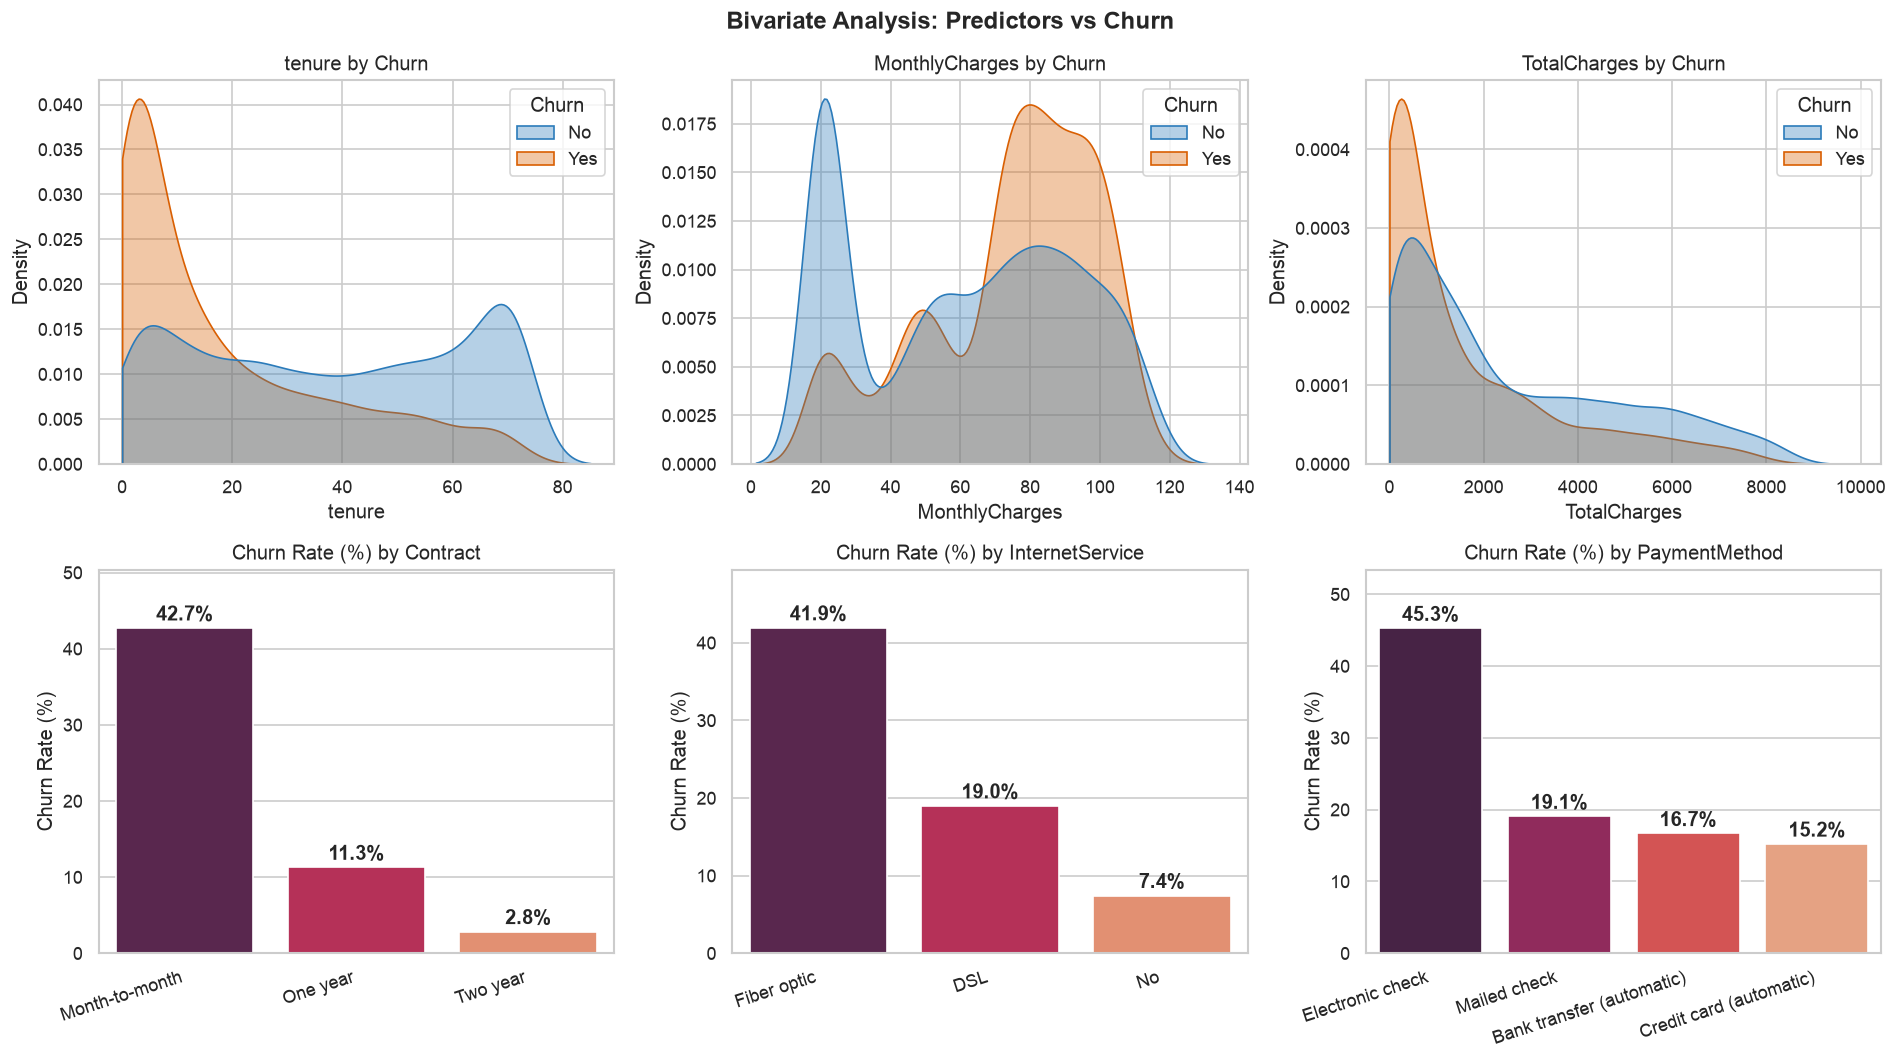

In [ ]:
# 4. Bivariate Analysis: Numerical & Categorical Features vs Churn
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
churn_colors = {"No": "#2b7bba", "Yes": "#d95f02"}

for ax, col in zip(axes[0], num_cols):
    sns.kdeplot(data=eda_df, x=col, hue="Churn", hue_order=["No", "Yes"],
                palette=churn_colors, fill=True, common_norm=False, clip=(0, None), alpha=0.35, ax=ax)
    ax.set_title(f"{col} by Churn")

for ax, col in zip(axes[1], ["Contract", "InternetService", "PaymentMethod"]):
    rates = (eda_df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
             .sort_values(ascending=False))
    sns.barplot(x=rates.index, y=rates.values, hue=rates.index, palette="rocket", legend=False, ax=ax)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 1.0, f"{v:.1f}%", ha="center", fontweight="bold")
    ax.set_title(f"Churn Rate (%) by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, max(rates.values) * 1.18)
    ax.tick_params(axis="x", rotation=18)
    for tick in ax.get_xticklabels():
        tick.set_ha("right")

plt.suptitle("Bivariate Analysis: Predictors vs Churn", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "04_bivariate_churn_analysis.png"), dpi=200, bbox_inches="tight")
plt.show()

**Observation:**
- Churners concentrate heavily in low `tenure` (median `10` months vs `38` months for retained) and higher `MonthlyCharges` (median `$79.65` vs `$64.43`).
- `Month-to-month` contracts have **42.7%** churn vs **2.8%** on `Two year` contracts; `Fiber optic` shows **41.9%** churn; `Electronic check` shows **45.3%** churn.

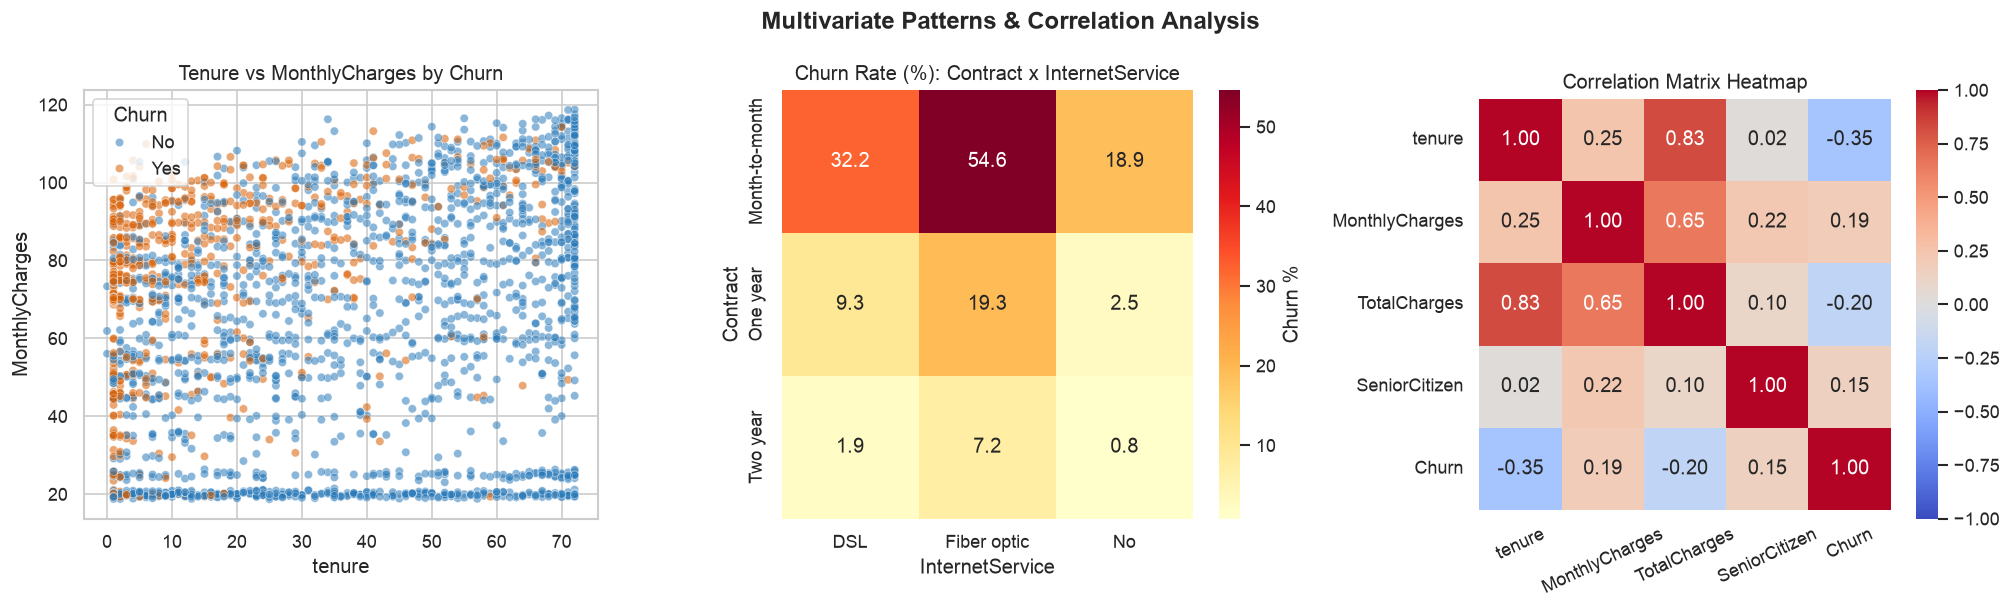

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outliers
0,tenure,9.00,55.00,46.00,-60.00,124.00,0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0
2,TotalCharges,401.45,3794.74,3393.29,-4688.48,8884.67,0


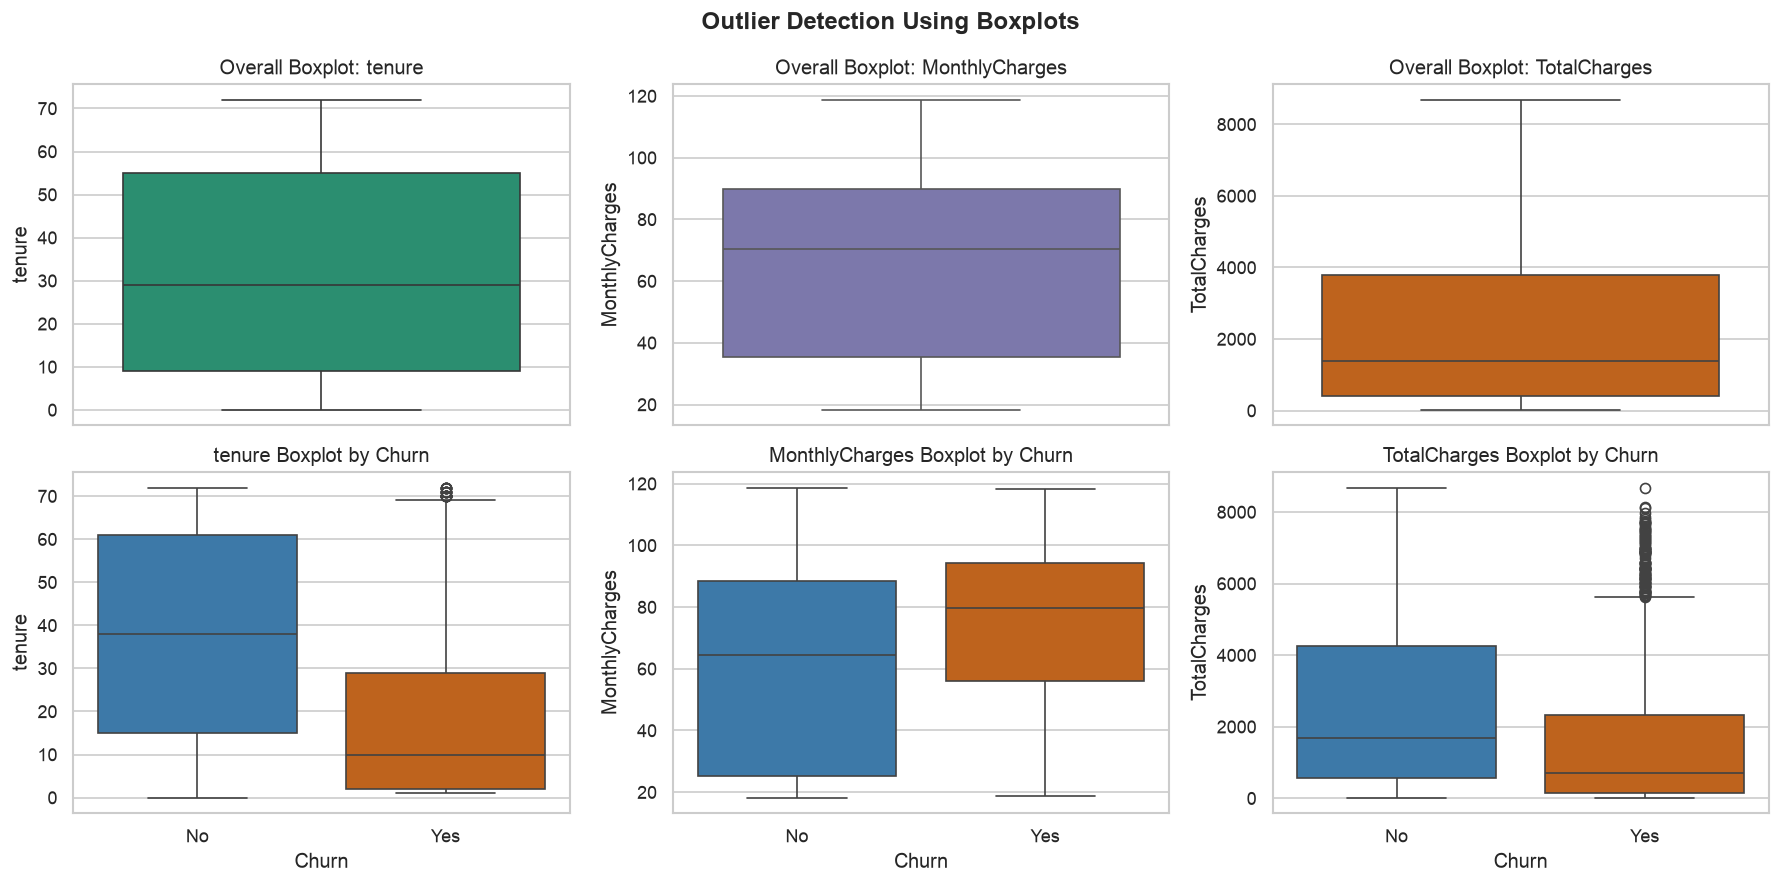

In [ ]:
# 5. Multivariate Analysis & Correlation Heatmap
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(data=eda_df.sample(2500, random_state=RANDOM_STATE),
                x="tenure", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"],
                palette={"No": "#2b7bba", "Yes": "#d95f02"}, alpha=0.55, s=25, ax=axes[0])
axes[0].set_title("Tenure vs MonthlyCharges by Churn")

piv = eda_df.assign(ChurnFlag=(eda_df["Churn"] == "Yes").astype(int)).pivot_table(
    index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean"
) * 100
sns.heatmap(piv, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Churn %"}, ax=axes[1])
axes[1].set_title("Churn Rate (%): Contract x InternetService")

corr_df = eda_df[num_cols].copy()
corr_df["SeniorCitizen"] = (eda_df["SeniorCitizen"] == "Yes").astype(int)
corr_df["Churn"] = (eda_df["Churn"] == "Yes").astype(int)
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=axes[2])
axes[2].set_title("Correlation Matrix Heatmap")
axes[2].tick_params(axis="x", rotation=25)

plt.suptitle("Multivariate Patterns & Correlation Analysis", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "05_multivariate_and_correlation.png"), dpi=200, bbox_inches="tight")
plt.show()

# 6. Outlier Detection Using Boxplots & IQR Bounds
iqr_rows = []
for col in num_cols:
    q1, q3 = eda_df[col].quantile(0.25), eda_df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((eda_df[col] < low) | (eda_df[col] > high)).sum())
    iqr_rows.append({"Feature": col, "Q1": round(q1, 2), "Q3": round(q3, 2),
                     "IQR": round(iqr, 2), "Lower_Bound": round(low, 2),
                     "Upper_Bound": round(high, 2), "Outliers": n_out})
display(pd.DataFrame(iqr_rows))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for idx, (col, color) in enumerate(zip(num_cols, ["#1b9e77", "#7570b3", "#d95f02"])):
    sns.boxplot(y=eda_df[col], color=color, ax=axes[0, idx])
    axes[0, idx].set_title(f"Overall Boxplot: {col}")
    sns.boxplot(data=eda_df, x="Churn", y=col, order=["No", "Yes"], hue="Churn",
                palette={"No": "#2b7bba", "Yes": "#d95f02"}, legend=False, ax=axes[1, idx])
    axes[1, idx].set_title(f"{col} Boxplot by Churn")

plt.suptitle("Outlier Detection Using Boxplots", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "06_outlier_boxplots.png"), dpi=200, bbox_inches="tight")
plt.show()

**Observation:**
- **Multivariate:** `Month-to-month` + `Fiber optic` reaches **54.6% churn**, compared to just **0.8%** for `Two year` + `No internet`.
- **Correlation:** `tenure` and `TotalCharges` are strongly correlated ($r = 0.83$), and `MonthlyCharges` correlates with `TotalCharges` ($r = 0.65$), confirming redundancy across billing columns.
- **Outliers:** Global IQR bounds find `0` extreme outliers across all three numerical features, so no records need clipping or removal.

## 3. Data Cleaning, Preprocessing Pipeline & Train-Test Split

Using **Scikit-learn** (`LabelEncoder`, `train_test_split`, `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`):
- Drop `customerID` (no predictive value).
- Coerce `TotalCharges` blanks to `NaN` so `SimpleImputer(strategy='median')` imputes them cleanly **inside** the training fold/split (no data leakage!).
- Encode target `Churn` with `LabelEncoder()` (`No -> 0`, `Yes -> 1`).
- Split `80%` Training / `20%` Test with `stratify=y` so both sets keep the `26.54%` churn rate.
- Build a reusable `ColumnTransformer` that imputes and scales numerical columns and imputes and one-hot encodes categorical columns (`drop='if_binary'`).

In [ ]:
# Clean dataset
df_clean = raw_df.drop(columns=["customerID"]).copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"].str.strip(), errors="coerce")
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df_clean.drop(columns=["Churn"])
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df_clean["Churn"])  # No=0, Yes=1
print("Target classes:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Train shape: {X_train.shape} (churn={y_train.mean():.4f}) | Test shape: {X_test.shape} (churn={y_test.mean():.4f})")

num_features = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_features = [c for c in X.columns if c not in num_features]

def make_preprocessor(scale_all=False):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)),
    ])
    ct = ColumnTransformer([
        ("num", num_pipe, num_features),
        ("cat", cat_pipe, cat_features),
    ])
    if scale_all:
        return Pipeline([("ct", ct), ("full_scaler", StandardScaler())])
    return Pipeline([("ct", ct)])

# Fit strictly on X_train to check output feature space
sample_prep = make_preprocessor(scale_all=False)
X_train_encoded = sample_prep.fit_transform(X_train)
X_test_encoded = sample_prep.transform(X_test)
feature_names = [f.replace("num__", "").replace("cat__", "") for f in sample_prep.named_steps["ct"].get_feature_names_out()]

print(f"Encoded feature count: {len(feature_names)} | Missing after imputation: {np.isnan(X_train_encoded).sum()}")

Target classes: {'No': np.int64(0), 'Yes': np.int64(1)}
Train shape: (5634, 19) (churn=0.2654) | Test shape: (1409, 19) (churn=0.2654)
Encoded feature count: 40 | Missing after imputation: 0


## 4. Unsupervised Learning: K-Means & DBSCAN Only

Clustering discovers natural customer groups using **only input features `X`** (never `y`). All 40 encoded features are standardized via `StandardScaler` so distances are balanced across numerical and categorical features.

### A. K-Means Clustering
K-Means partitions points into $k$ clusters by minimizing within-cluster inertia (sum of squared distances to cluster centroids). We sweep $k = 2..10$ using the **Elbow Method** and validate cluster separation with **Silhouette**, **Davies-Bouldin** (lower is better), and **Calinski-Harabasz** (higher is better) scores.

### B. DBSCAN
DBSCAN groups dense neighborhoods having at least `min_samples` points within radius `eps`, and marks sparse boundary points as **noise (`-1`)**. We experiment with `eps` and `min_samples` and compare DBSCAN directly against K-Means.

,k,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,204767.4,0.2985,1.1731,2646.0
1,3,176658.6,0.2291,1.9030,2093.4
2,4,160891.4,0.2391,1.7692,1762.1
3,5,151788.5,0.2028,1.9564,1506.1
4,6,145783.8,0.1906,2.1700,1312.3
5,7,141201.2,0.1884,2.2270,1167.0
6,8,137100.9,0.1259,2.3155,1060.1
7,9,133590.2,0.1228,2.2785,974.9
8,10,130614.5,0.1242,2.3097,904.0


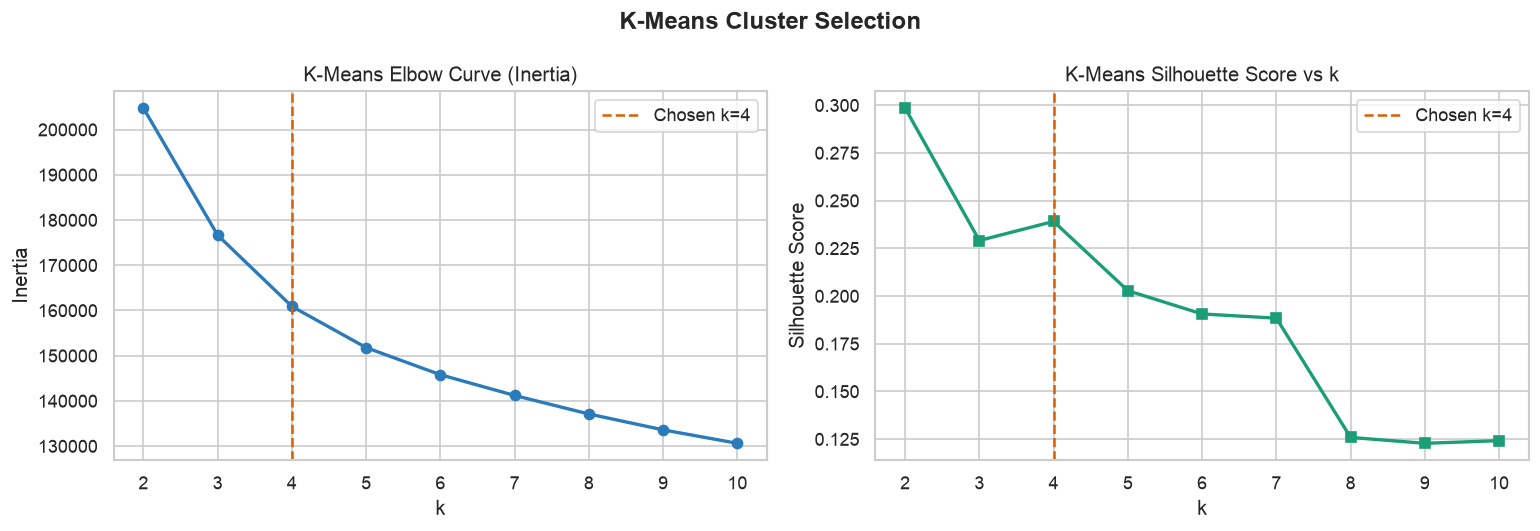

=== K-Means (k=4) Segment Profiles ===


,Customers,Avg_Tenure,Avg_Monthly,Top_Contract,Top_Internet,PostHoc_Churn_Pct
Cluster,,,,,,
0,682,31.74,42.03,Month-to-month,DSL,24.93
1,1526,30.55,21.08,Two year,No,7.40
2,2757,16.48,74.11,Month-to-month,Fiber optic,46.50
3,2078,55.00,91.90,Two year,Fiber optic,14.63


In [ ]:
# Scale all features without target y for unsupervised clustering
X_unsup = make_preprocessor(scale_all=True).fit_transform(X)

# --- A. K-Means Elbow Sweep ---
kmeans_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_unsup)
    kmeans_rows.append({
        "k": k,
        "Inertia": round(km.inertia_, 1),
        "Silhouette": round(silhouette_score(X_unsup, labels), 4),
        "Davies_Bouldin": round(davies_bouldin_score(X_unsup, labels), 4),
        "Calinski_Harabasz": round(calinski_harabasz_score(X_unsup, labels), 1),
    })
kmeans_elbow_df = pd.DataFrame(kmeans_rows)
display(kmeans_elbow_df)

chosen_k = 4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(kmeans_elbow_df["k"], kmeans_elbow_df["Inertia"], marker="o", linewidth=2, color="#2b7bba")
axes[0].axvline(chosen_k, color="#d95f02", linestyle="--", label=f"Chosen k={chosen_k}")
axes[0].set_title("K-Means Elbow Curve (Inertia)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].legend()

axes[1].plot(kmeans_elbow_df["k"], kmeans_elbow_df["Silhouette"], marker="s", linewidth=2, color="#1b9e77")
axes[1].axvline(chosen_k, color="#d95f02", linestyle="--", label=f"Chosen k={chosen_k}")
axes[1].set_title("K-Means Silhouette Score vs k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

plt.suptitle("K-Means Cluster Selection", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "07_kmeans_elbow_and_metrics.png"), dpi=200, bbox_inches="tight")
plt.show()

km_final = KMeans(n_clusters=chosen_k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
km_labels = km_final.fit_predict(X_unsup)

km_profile = df_clean.assign(Cluster=km_labels, ChurnFlag=y).groupby("Cluster").agg(
    Customers=("Cluster", "count"),
    Avg_Tenure=("tenure", "mean"),
    Avg_Monthly=("MonthlyCharges", "mean"),
    Top_Contract=("Contract", lambda s: s.mode()[0]),
    Top_Internet=("InternetService", lambda s: s.mode()[0]),
    PostHoc_Churn_Pct=("ChurnFlag", lambda s: round(s.mean() * 100, 2)),
).round(2)
print("=== K-Means (k=4) Segment Profiles ===")
display(km_profile)

,eps,min_samples,Clusters,Noise_Points,Noise_Pct,Silhouette_NonNoise
4,3.5,5,17,1432,20.33,0.0619
5,3.5,10,5,2146,30.47,0.1878
6,3.5,15,3,2558,36.32,0.2942
7,3.5,20,4,2820,40.04,0.2652
8,4.0,5,9,440,6.25,0.0646
9,4.0,10,5,944,13.40,0.1796
10,4.0,15,4,1336,18.97,0.2299
11,4.0,20,4,1565,22.22,0.2295
12,4.5,5,3,37,0.53,0.2517
13,4.5,10,3,120,1.70,0.2525


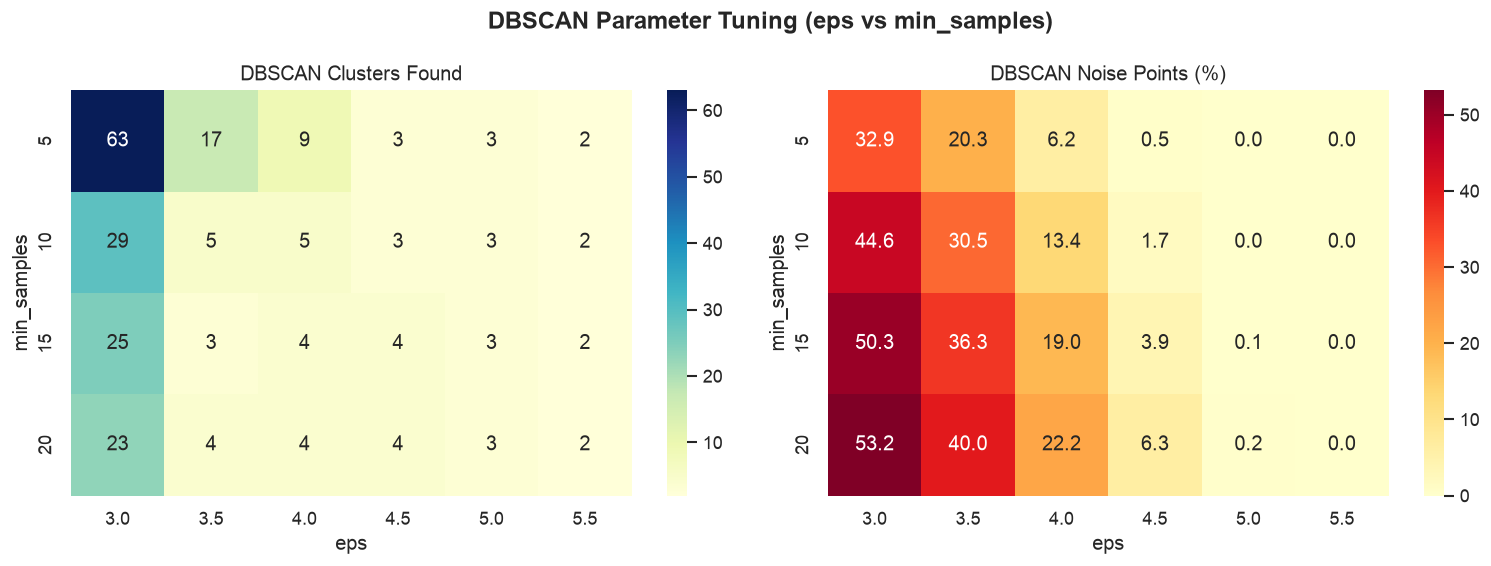

=== K-Means vs DBSCAN Comparison (DBSCAN metrics computed on non-noise points) ===


,Algorithm,Clusters,Noise_Points,Noise_Pct,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,K-Means (k=4),4,0,0.0,0.2391,1.7692,1762.1
1,"DBSCAN (eps=4.5, min_samples=15)",4,275,3.9,0.2143,1.5896,1214.6


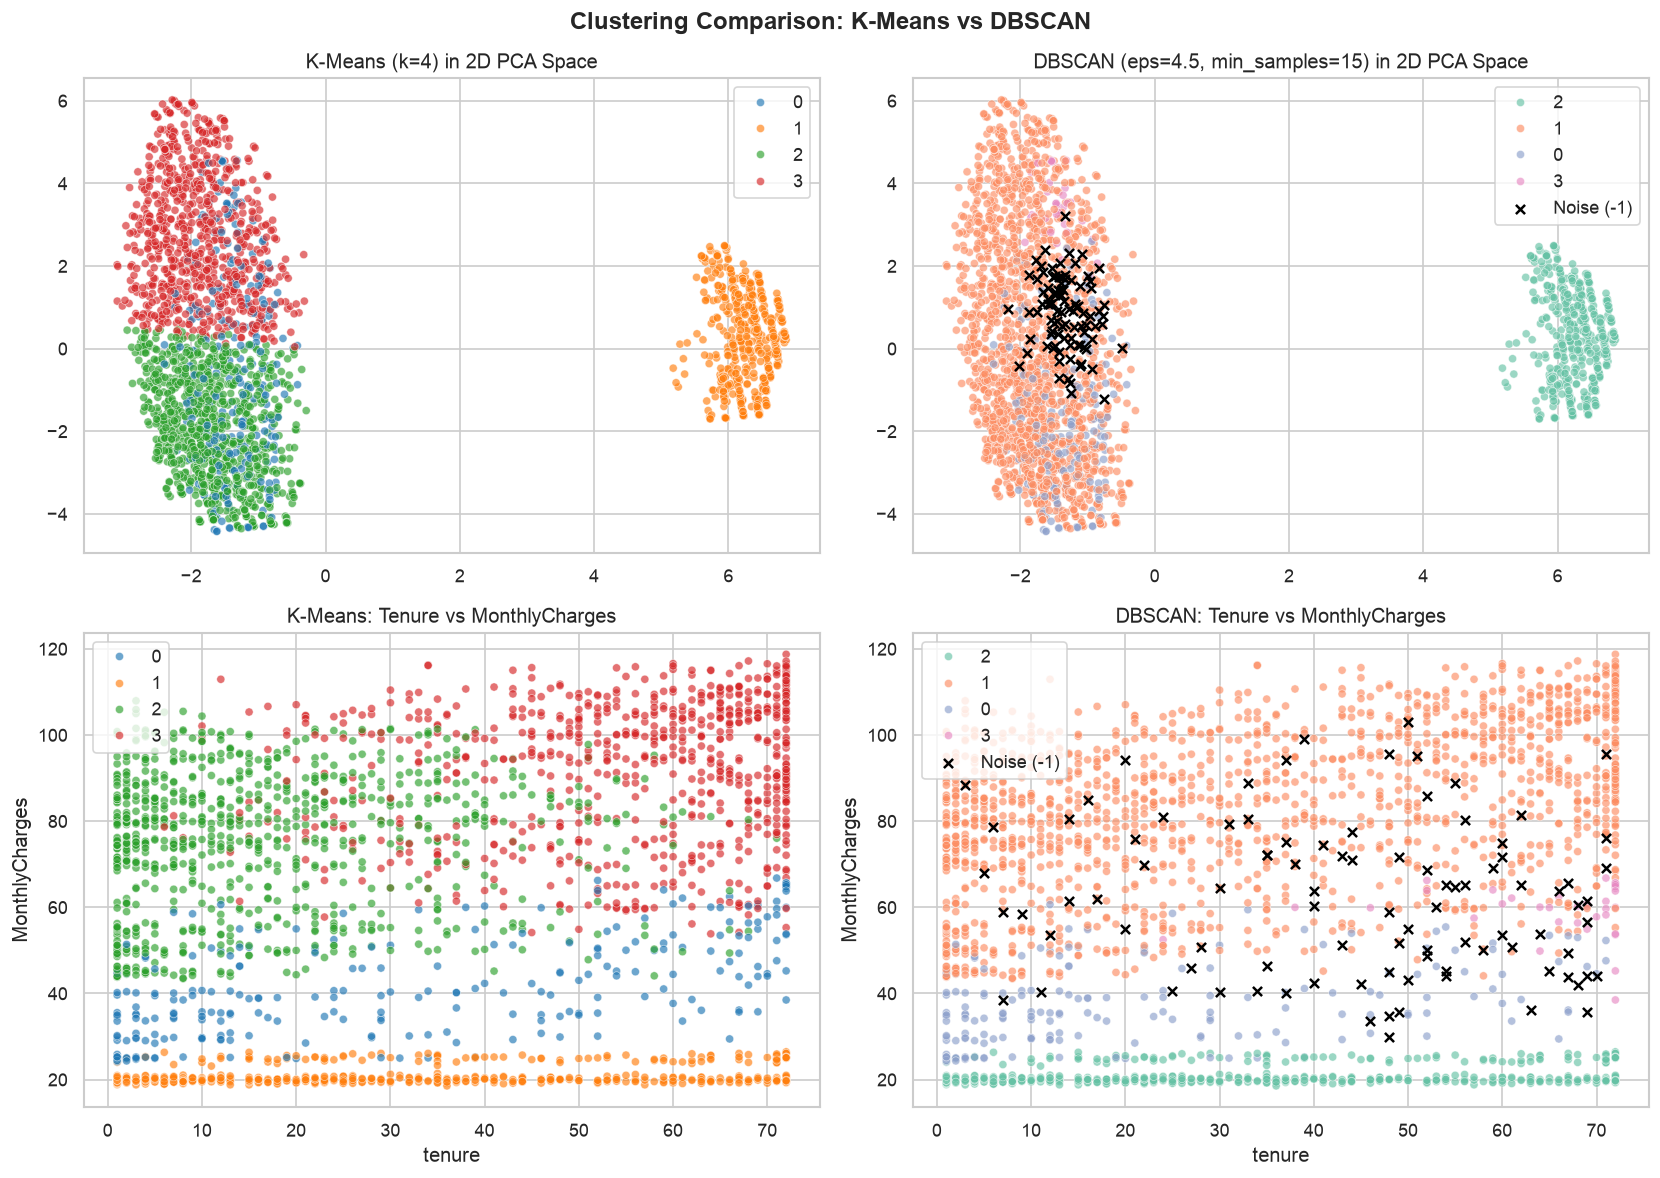

In [ ]:
# --- B. DBSCAN Hyperparameter Experiment ---
db_rows = []
for eps in [3.0, 3.5, 4.0, 4.5, 5.0, 5.5]:
    for ms in [5, 10, 15, 20]:
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X_unsup)
        n_clusters = len(set(labels) - {-1})
        noise_count = int((labels == -1).sum())
        mask = labels != -1
        sil = (silhouette_score(X_unsup[mask], labels[mask])
               if n_clusters >= 2 and mask.sum() > n_clusters else np.nan)
        db_rows.append({
            "eps": eps, "min_samples": ms, "Clusters": n_clusters,
            "Noise_Points": noise_count, "Noise_Pct": round(noise_count / len(labels) * 100, 2),
            "Silhouette_NonNoise": round(sil, 4) if not np.isnan(sil) else np.nan,
        })
db_tune_df = pd.DataFrame(db_rows)
display(db_tune_df[db_tune_df["eps"].isin([3.5, 4.0, 4.5, 5.0])])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(db_tune_df.pivot(index="min_samples", columns="eps", values="Clusters"),
            annot=True, fmt="d", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("DBSCAN Clusters Found")
sns.heatmap(db_tune_df.pivot(index="min_samples", columns="eps", values="Noise_Pct"),
            annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("DBSCAN Noise Points (%)")
plt.suptitle("DBSCAN Parameter Tuning (eps vs min_samples)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "08_dbscan_parameter_tuning.png"), dpi=200, bbox_inches="tight")
plt.show()

# Fit chosen DBSCAN configuration
db_final = DBSCAN(eps=4.5, min_samples=15)
db_labels = db_final.fit_predict(X_unsup)
inliers = db_labels != -1

# Compare K-Means vs DBSCAN
cluster_compare = pd.DataFrame([
    {
        "Algorithm": "K-Means (k=4)",
        "Clusters": 4, "Noise_Points": 0, "Noise_Pct": 0.0,
        "Silhouette": round(silhouette_score(X_unsup, km_labels), 4),
        "Davies_Bouldin": round(davies_bouldin_score(X_unsup, km_labels), 4),
        "Calinski_Harabasz": round(calinski_harabasz_score(X_unsup, km_labels), 1),
    },
    {
        "Algorithm": "DBSCAN (eps=4.5, min_samples=15)",
        "Clusters": len(set(db_labels) - {-1}),
        "Noise_Points": int((~inliers).sum()),
        "Noise_Pct": round((~inliers).mean() * 100, 2),
        "Silhouette": round(silhouette_score(X_unsup[inliers], db_labels[inliers]), 4),
        "Davies_Bouldin": round(davies_bouldin_score(X_unsup[inliers], db_labels[inliers]), 4),
        "Calinski_Harabasz": round(calinski_harabasz_score(X_unsup[inliers], db_labels[inliers]), 1),
    },
])
print("=== K-Means vs DBSCAN Comparison (DBSCAN metrics computed on non-noise points) ===")
display(cluster_compare)

# Visualize both in 2D PCA projection & Tenure-MonthlyCharges space
pca_vis = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_unsup)
idx_sub = np.random.default_rng(RANDOM_STATE).choice(len(X_unsup), size=2500, replace=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(x=pca_vis[idx_sub, 0], y=pca_vis[idx_sub, 1], hue=km_labels[idx_sub].astype(str),
                palette="tab10", s=24, alpha=0.65, ax=axes[0, 0])
axes[0, 0].set_title("K-Means (k=4) in 2D PCA Space")

db_sub = db_labels[idx_sub]
mask_sub = db_sub != -1
sns.scatterplot(x=pca_vis[idx_sub[mask_sub], 0], y=pca_vis[idx_sub[mask_sub], 1],
                hue=db_sub[mask_sub].astype(str), palette="Set2", s=24, alpha=0.65, ax=axes[0, 1])
axes[0, 1].scatter(pca_vis[idx_sub[~mask_sub], 0], pca_vis[idx_sub[~mask_sub], 1],
                   c="black", marker="x", s=30, label="Noise (-1)")
axes[0, 1].set_title("DBSCAN (eps=4.5, min_samples=15) in 2D PCA Space")
axes[0, 1].legend()

sns.scatterplot(x=df_clean["tenure"].iloc[idx_sub], y=df_clean["MonthlyCharges"].iloc[idx_sub],
                hue=km_labels[idx_sub].astype(str), palette="tab10", s=24, alpha=0.65, ax=axes[1, 0])
axes[1, 0].set_title("K-Means: Tenure vs MonthlyCharges")

sns.scatterplot(x=df_clean["tenure"].iloc[idx_sub[mask_sub]], y=df_clean["MonthlyCharges"].iloc[idx_sub[mask_sub]],
                hue=db_sub[mask_sub].astype(str), palette="Set2", s=24, alpha=0.65, ax=axes[1, 1])
axes[1, 1].scatter(df_clean["tenure"].iloc[idx_sub[~mask_sub]], df_clean["MonthlyCharges"].iloc[idx_sub[~mask_sub]],
                   c="black", marker="x", s=30, label="Noise (-1)")
axes[1, 1].set_title("DBSCAN: Tenure vs MonthlyCharges")
axes[1, 1].legend()

plt.suptitle("Clustering Comparison: K-Means vs DBSCAN", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "09_clustering_comparison_kmeans_vs_dbscan.png"), dpi=200, bbox_inches="tight")
plt.show()

**Clustering Takeaways:**
- **K-Means (`k=4`)** partitions every customer cleanly into 4 intuitive business segments (including a high-risk early Fiber Optic group with `46.50%` churn vs a No-Internet group with `7.40%` churn).
- **DBSCAN (`eps=4.5, min_samples=15`)** finds `4` dense clusters AND flags `275` (`3.9%`) unusual/borderline customers as noise (`-1`), achieving tighter Davies-Bouldin separation (`1.5896` vs `1.7692`) on core clusters, though it is much more sensitive to `eps` in 40 dimensions.

## 5. Feature Selection: Filter, Wrapper (RFE), and Embedded Methods

All feature selection is performed strictly on `X_train, y_train` using Scikit-learn:
1. **Filter (`SelectKBest` with `f_classif`)**: Ranks each feature independently via one-way ANOVA F-statistics.
2. **Wrapper (`RFE`)**: Uses `LogisticRegression` weights recursively to eliminate weak features jointly.
3. **Embedded (`SelectFromModel` with L1 `LogisticRegression`)**: Uses $L_1$ sparsity (`l1_ratio=1.0, solver='liblinear', C=0.1`) during training to zero out redundant features automatically.

Best CV k -> Filter: 30 | Wrapper (RFE): 20


Selected counts -> Filter: 30, RFE: 20, Embedded L1: 23
Consensus features selected by ALL 3 methods: ['Contract_Month-to-month', 'tenure', 'PaymentMethod_Electronic check', 'Contract_Two year', 'OnlineBackup_No internet service', 'MonthlyCharges', 'PaperlessBilling_Yes', 'TotalCharges', 'OnlineSecurity_Yes', 'InternetService_DSL']


,Feature,Filter_F_Score,Filter_Selected,RFE_Rank,RFE_Selected,Embedded_Abs_Coef,Embedded_Selected,Votes
0,Contract_Month-to-month,1114.22,True,1,True,0.0453,True,3
1,tenure,763.89,True,1,True,0.8412,True,3
2,PaymentMethod_Electronic check,595.42,True,1,True,0.3282,True,3
3,Contract_Two year,566.07,True,1,True,1.1247,True,3
4,OnlineBackup_No internet service,311.49,True,1,True,0.0931,True,3
5,MonthlyCharges,229.90,True,1,True,0.8823,True,3
6,PaperlessBilling_Yes,229.76,True,1,True,0.2963,True,3
7,TotalCharges,221.21,True,1,True,0.0294,True,3
8,OnlineSecurity_Yes,177.05,True,1,True,0.5071,True,3
9,InternetService_DSL,94.77,True,1,True,0.1164,True,3


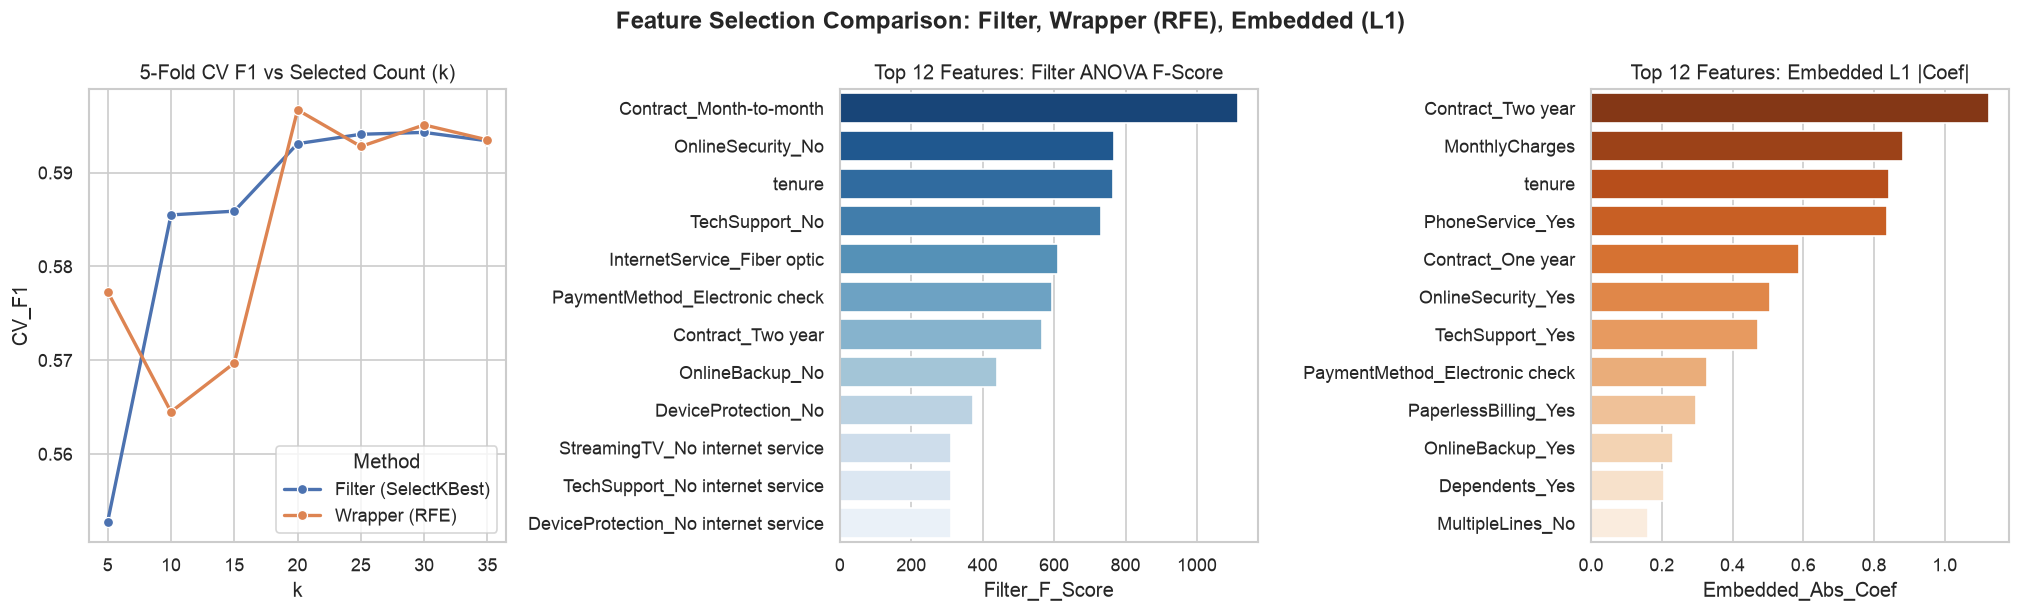

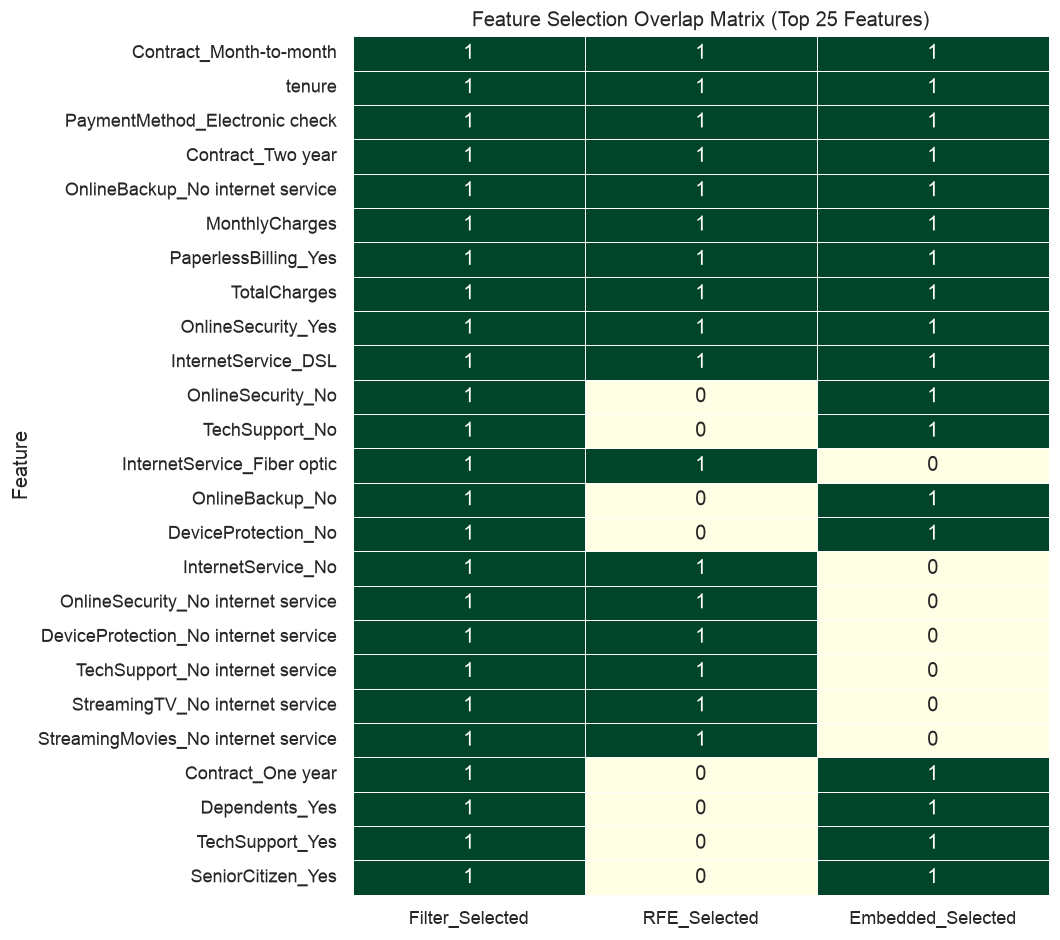

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_list = [5, 10, 15, 20, 25, 30, 35]
sweep_rows = []

for k in k_list:
    pipe_flt = Pipeline([
        ("prep", make_preprocessor()),
        ("sel", SelectKBest(score_func=f_classif, k=k)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    pipe_rfe = Pipeline([
        ("prep", make_preprocessor()),
        ("sel", RFE(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), n_features_to_select=k)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    sweep_rows.append({"Method": "Filter (SelectKBest)", "k": k,
                       "CV_F1": round(cross_val_score(pipe_flt, X_train, y_train, cv=skf, scoring="f1").mean(), 4)})
    sweep_rows.append({"Method": "Wrapper (RFE)", "k": k,
                       "CV_F1": round(cross_val_score(pipe_rfe, X_train, y_train, cv=skf, scoring="f1").mean(), 4)})

sweep_df = pd.DataFrame(sweep_rows)
best_filter_k = int(sweep_df[sweep_df["Method"] == "Filter (SelectKBest)"].sort_values("CV_F1", ascending=False).iloc[0]["k"])
best_rfe_k = int(sweep_df[sweep_df["Method"] == "Wrapper (RFE)"].sort_values("CV_F1", ascending=False).iloc[0]["k"])
print(f"Best CV k -> Filter: {best_filter_k} | Wrapper (RFE): {best_rfe_k}")

# Fit all 3 selectors on preprocessed training features
filter_sel = SelectKBest(score_func=f_classif, k=best_filter_k).fit(X_train_encoded, y_train)
rfe_sel = RFE(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), n_features_to_select=best_rfe_k).fit(X_train_encoded, y_train)
emb_sel = SelectFromModel(LogisticRegression(C=0.1, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **L1_KWARGS)).fit(X_train_encoded, y_train)

fs_df = pd.DataFrame({
    "Feature": feature_names,
    "Filter_F_Score": np.round(filter_sel.scores_, 2),
    "Filter_Selected": filter_sel.get_support(),
    "RFE_Rank": rfe_sel.ranking_,
    "RFE_Selected": rfe_sel.get_support(),
    "Embedded_Abs_Coef": np.round(np.abs(emb_sel.estimator_.coef_.ravel()), 4),
    "Embedded_Selected": emb_sel.get_support(),
})
fs_df["Votes"] = fs_df["Filter_Selected"].astype(int) + fs_df["RFE_Selected"].astype(int) + fs_df["Embedded_Selected"].astype(int)
fs_df = fs_df.sort_values(["Votes", "Filter_F_Score"], ascending=[False, False]).reset_index(drop=True)

print(f"Selected counts -> Filter: {best_filter_k}, RFE: {best_rfe_k}, Embedded L1: {int(emb_sel.get_support().sum())}")
print("Consensus features selected by ALL 3 methods:", fs_df[fs_df["Votes"] == 3]["Feature"].tolist())
display(fs_df.head(15))

# Visualize tuning curve & top feature scores
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
sns.lineplot(data=sweep_df, x="k", y="CV_F1", hue="Method", marker="o", linewidth=2, ax=axes[0])
axes[0].set_title("5-Fold CV F1 vs Selected Count (k)")

top_flt = fs_df.sort_values("Filter_F_Score", ascending=False).head(12)
sns.barplot(data=top_flt, y="Feature", x="Filter_F_Score", hue="Feature", palette="Blues_r", legend=False, ax=axes[1])
axes[1].set_title("Top 12 Features: Filter ANOVA F-Score")
axes[1].set_ylabel("")

top_emb = fs_df.sort_values("Embedded_Abs_Coef", ascending=False).head(12)
sns.barplot(data=top_emb, y="Feature", x="Embedded_Abs_Coef", hue="Feature", palette="Oranges_r", legend=False, ax=axes[2])
axes[2].set_title("Top 12 Features: Embedded L1 |Coef|")
axes[2].set_ylabel("")

plt.suptitle("Feature Selection Comparison: Filter, Wrapper (RFE), Embedded (L1)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "10_feature_selection_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

# Consensus overlap matrix
overlap = fs_df.head(25).set_index("Feature")[["Filter_Selected", "RFE_Selected", "Embedded_Selected"]].astype(int)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(overlap, annot=True, fmt="d", cmap="YlGn", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("Feature Selection Overlap Matrix (Top 25 Features)")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "11_feature_selection_overlap.png"), dpi=200, bbox_inches="tight")
plt.show()

**Feature Selection Takeaways:**
- Univariate **Filter (`f_classif`)** scores all 6 redundant `*_No internet service` dummy columns identically, wasting several top slots.
- **Embedded L1 (`SelectFromModel`)** and **Wrapper (`RFE`)** automatically drop redundant dummy copies while preserving `Contract_Month-to-month`, `Contract_Two year`, `tenure`, `MonthlyCharges`, `TotalCharges`, `PaperlessBilling_Yes`, and `PaymentMethod_Electronic check`.

## 6. Dimensionality Reduction: Principal Component Analysis (PCA)

Before applying PCA, we standardize **all** 40 encoded features (`StandardScaler`) so features with larger scales do not dominate principal directions. We then examine explained variance, cumulative variance, 2D projection, and how much information is retained vs lost at the `95%` variance threshold.

Original dimensions : 40
PCA (95%) components: 18
Information retained: 95.79% | Information lost: 4.21%
2D PCA (PC1 + PC2)  : 42.27% variance retained


,PC,Explained_Variance_Pct,Cumulative_Variance_Pct
0,1,27.83,27.83
1,2,14.45,42.27
2,3,8.94,51.22
3,4,5.05,56.26
4,5,4.16,60.42
5,6,3.48,63.90
6,7,3.28,67.17
7,8,3.22,70.39
8,9,3.13,73.52
9,10,3.02,76.54


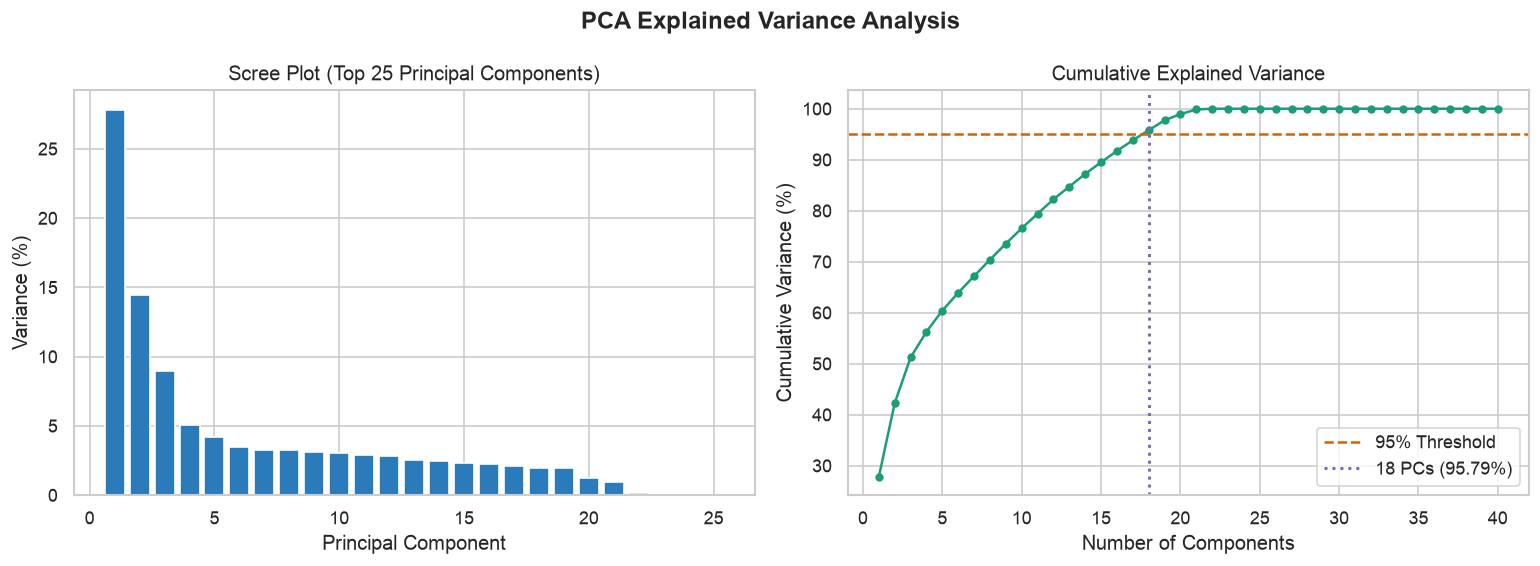

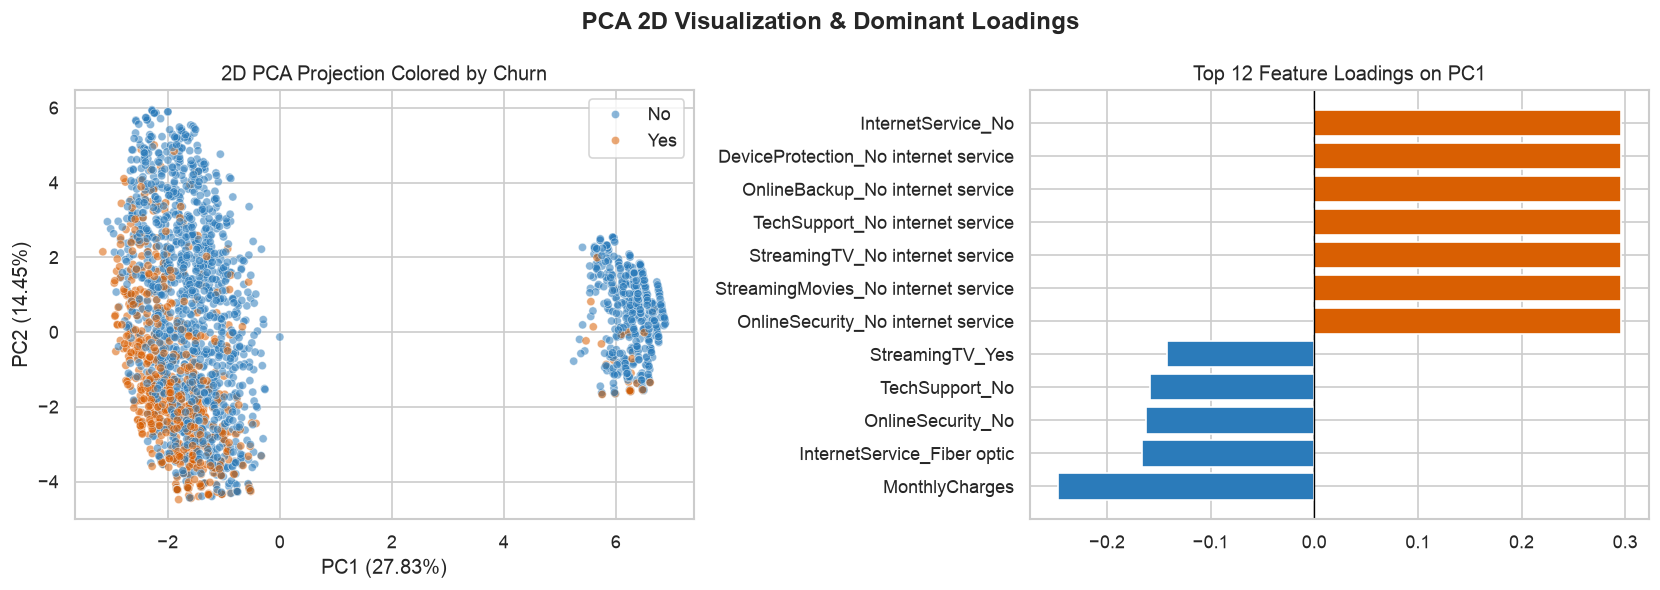

In [ ]:
# Standardize all 40 encoded features strictly on X_train before PCA
pca_scaler = make_preprocessor(scale_all=True)
X_train_std = pca_scaler.fit_transform(X_train)
X_test_std = pca_scaler.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_std)
evr = pca_full.explained_variance_ratio_
cum_var = np.cumsum(evr)

pca_95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train_std)
n_comp_95 = pca_95.n_components_
var_retained = pca_95.explained_variance_ratio_.sum()
var_lost = 1.0 - var_retained

print(f"Original dimensions : {X_train_std.shape[1]}")
print(f"PCA (95%) components: {n_comp_95}")
print(f"Information retained: {var_retained * 100:.2f}% | Information lost: {var_lost * 100:.2f}%")
print(f"2D PCA (PC1 + PC2)  : {cum_var[1] * 100:.2f}% variance retained")

pca_table = pd.DataFrame({
    "PC": np.arange(1, len(evr) + 1),
    "Explained_Variance_Pct": np.round(evr * 100, 2),
    "Cumulative_Variance_Pct": np.round(cum_var * 100, 2),
})
display(pca_table.head(20))

# Scree & Cumulative Variance Graph
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(pca_table["PC"][:25], pca_table["Explained_Variance_Pct"][:25], color="#2b7bba")
axes[0].set_title("Scree Plot (Top 25 Principal Components)")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Variance (%)")

axes[1].plot(pca_table["PC"], pca_table["Cumulative_Variance_Pct"], marker="o", markersize=4, color="#1b9e77")
axes[1].axhline(95.0, color="#d95f02", linestyle="--", label="95% Threshold")
axes[1].axvline(n_comp_95, color="#7570b3", linestyle=":", linewidth=1.8, label=f"{n_comp_95} PCs ({var_retained*100:.2f}%)")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].legend()

plt.suptitle("PCA Explained Variance Analysis", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "12_pca_explained_variance.png"), dpi=200, bbox_inches="tight")
plt.show()

# 2D PCA Visualization & PC1 Loadings
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_tr_2d = pca_2d.fit_transform(X_train_std)
idx_tr = np.random.default_rng(RANDOM_STATE).choice(len(X_tr_2d), size=2500, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_tr_2d[idx_tr, 0], y=X_tr_2d[idx_tr, 1],
                hue=np.where(y_train[idx_tr] == 1, "Yes", "No"),
                hue_order=["No", "Yes"], palette={"No": "#2b7bba", "Yes": "#d95f02"},
                alpha=0.55, s=24, ax=axes[0])
axes[0].set_title("2D PCA Projection Colored by Churn")
axes[0].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}%)")
axes[0].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}%)")

loadings = pd.Series(pca_2d.components_[0], index=feature_names)
top_load = loadings.reindex(loadings.abs().sort_values(ascending=False).head(12).index).sort_values()
axes[1].barh(top_load.index, top_load.values, color=["#d95f02" if v > 0 else "#2b7bba" for v in top_load.values])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Top 12 Feature Loadings on PC1")

plt.suptitle("PCA 2D Visualization & Dominant Loadings", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "13_pca_2d_projection.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7 & 8. Stratified 5-Fold Cross-Validation & Ensemble Learning

### Supervised Pipelines Built Strictly With Scikit-learn
We compare all feature representations (`Original`, `Filter`, `Wrapper RFE`, `Embedded L1`, `PCA`) alongside the three required ensemble techniques:
- **Bagging (`BaggingClassifier`)**: Fits 100 `DecisionTreeClassifier` models on 80% bootstrap samples (`max_samples=0.8`) and averages predictions to **reduce variance**.
- **Boosting (`GradientBoostingClassifier`)**: Sequentially fits 150 shallow trees (`max_depth=3`) on log-loss pseudo-residuals to **reduce bias**.
- **Stacking (`StackingClassifier`)**: Combines `LogisticRegression`, `BaggingClassifier`, and `GradientBoostingClassifier` out-of-fold probabilities using a `LogisticRegression` meta-learner.

We run **Stratified 5-Fold Cross-Validation** (`StratifiedKFold`, `cross_validate`) on the training set (`X_train, y_train`) so the hold-out test set remains completely untouched until final evaluation.

In [ ]:
# Verify class ratio preservation across all 5 Stratified folds
fold_check = []
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    fold_check.append({
        "Fold": fold,
        "Train_Size": len(tr_idx),
        "Val_Size": len(val_idx),
        "Train_Churn_Pct": round(y_train[tr_idx].mean() * 100, 2),
        "Val_Churn_Pct": round(y_train[val_idx].mean() * 100, 2),
    })
print("=== Stratified 5-Fold Class Balance Check ===")
display(pd.DataFrame(fold_check))

def make_bagging():
    return BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
        n_estimators=100, max_samples=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )

def make_boosting():
    return GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.9, random_state=RANDOM_STATE
    )

models = {
    "Original Features (LogisticRegression)": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Original Features (DecisionTree)": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE)),
    ]),
    f"Filter Selection (SelectKBest k={best_filter_k} + LR)": Pipeline([
        ("prep", make_preprocessor()),
        ("sel", SelectKBest(score_func=f_classif, k=best_filter_k)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    f"Wrapper Selection (RFE k={best_rfe_k} + LR)": Pipeline([
        ("prep", make_preprocessor()),
        ("sel", RFE(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), n_features_to_select=best_rfe_k)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Embedded Selection (L1 SelectFromModel + LR)": Pipeline([
        ("prep", make_preprocessor()),
        ("sel", SelectFromModel(LogisticRegression(C=0.1, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **L1_KWARGS))),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "PCA (95% Var + LR)": Pipeline([
        ("prep", make_preprocessor(scale_all=True)),
        ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Bagging (BaggingClassifier)": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", make_bagging()),
    ]),
    "Boosting (GradientBoostingClassifier)": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", make_boosting()),
    ]),
    "Stacking (StackingClassifier)": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", StackingClassifier(
            estimators=[
                ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                ("bag", make_bagging()),
                ("gb", make_boosting()),
            ],
            final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            cv=5, n_jobs=-1
        )),
    ]),
}

# Run Stratified 5-Fold cross_validate for all models
cv_summary_rows = []
fold_f1_rows = []

for name, pipe in models.items():
    scores = cross_validate(
        pipe, X_train, y_train, cv=skf,
        scoring=["accuracy", "precision", "recall", "f1"]
    )
    cv_summary_rows.append({
        "Model": name,
        "CV_Accuracy_Mean": round(scores["test_accuracy"].mean(), 4),
        "CV_Accuracy_Std": round(scores["test_accuracy"].std(ddof=1), 4),
        "CV_Precision_Mean": round(scores["test_precision"].mean(), 4),
        "CV_Recall_Mean": round(scores["test_recall"].mean(), 4),
        "CV_F1_Mean": round(scores["test_f1"].mean(), 4),
        "CV_F1_Std": round(scores["test_f1"].std(ddof=1), 4),
    })
    row_dict = {"Model": name}
    for i, (acc_val, f1_val) in enumerate(zip(scores["test_accuracy"], scores["test_f1"]), start=1):
        row_dict[f"Fold_{i}_F1"] = round(f1_val, 4)
        row_dict[f"Fold_{i}_Acc"] = round(acc_val, 4)
    fold_f1_rows.append(row_dict)

cv_summary_df = pd.DataFrame(cv_summary_rows)
fold_detail_df = pd.DataFrame(fold_f1_rows)

print("=== Individual Fold F1 & Accuracy Scores (Stratified 5-Fold CV) ===")
display(fold_detail_df)

=== Stratified 5-Fold Class Balance Check ===


,Fold,Train_Size,Val_Size,Train_Churn_Pct,Val_Churn_Pct
0,1,4507,1127,26.54,26.53
1,2,4507,1127,26.54,26.53
2,3,4507,1127,26.54,26.53
3,4,4507,1127,26.54,26.53
4,5,4508,1126,26.53,26.55


=== Individual Fold F1 & Accuracy Scores (Stratified 5-Fold CV) ===


,Model,Fold_1_F1,Fold_1_Acc,Fold_2_F1,Fold_2_Acc,Fold_3_F1,Fold_3_Acc,Fold_4_F1,Fold_4_Acc,Fold_5_F1,Fold_5_Acc
0,Original Features (LogisticRegression),0.5850,0.7986,0.5495,0.7817,0.5863,0.8021,0.6425,0.8163,0.6011,0.8126
1,Original Features (DecisionTree),0.5259,0.7728,0.5273,0.7773,0.5714,0.7870,0.6177,0.7968,0.5714,0.8108
2,Filter Selection (SelectKBest k=30 + LR),0.5887,0.8004,0.5568,0.7853,0.5804,0.7986,0.6345,0.8119,0.6113,0.8171
3,Wrapper Selection (RFE k=20 + LR),0.5949,0.8030,0.5531,0.7835,0.6076,0.8075,0.6285,0.8101,0.5993,0.8064
4,Embedded Selection (L1 SelectFromModel + LR),0.5815,0.7995,0.5488,0.7826,0.5882,0.8012,0.6343,0.8128,0.6011,0.8126
5,PCA (95% Var + LR),0.5861,0.7995,0.5468,0.7808,0.5762,0.7977,0.6471,0.8190,0.5912,0.8108
6,Bagging (BaggingClassifier),0.5741,0.7959,0.5366,0.7808,0.6230,0.8163,0.5854,0.8039,0.5859,0.8117
7,Boosting (GradientBoostingClassifier),0.5617,0.7950,0.5618,0.7924,0.6117,0.8119,0.6120,0.8110,0.6035,0.8179
8,Stacking (StackingClassifier),0.5784,0.8021,0.5522,0.7870,0.6119,0.8154,0.6137,0.8101,0.6062,0.8188


## 9 & 10. Hold-Out Test Evaluation, Metrics, Confusion Matrices & Final Comparison

Because `Churn` is a binary classification problem (`No` vs `Yes`), we evaluate using:
- **Accuracy:** Overall fraction of correct predictions (sensitive to class imbalance).
- **Precision:** Out of predicted churners, how many truly churned (`TP / (TP + FP)`).
- **Recall:** Out of actual churners, how many were caught (`TP / (TP + FN)`).
- **F1-Score:** Harmonic mean of Precision and Recall, ideal under class imbalance.
- **Confusion Matrix & Classification Report:** Complete breakdown of `TN, FP, FN, TP`.

*(Regression metrics MAE, MSE, RMSE, $R^2$ are omitted because the target variable is categorical binary classification.)*

In [ ]:
test_rows = []
predictions = {}
reports = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    reports[name] = classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=4)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_rows.append({
        "Model": name,
        "Test_Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test_Precision": round(precision_score(y_test, y_pred), 4),
        "Test_Recall": round(recall_score(y_test, y_pred), 4),
        "Test_F1_Score": round(f1_score(y_test, y_pred), 4),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })

test_summary_df = pd.DataFrame(test_rows)
comparison_df = pd.merge(test_summary_df, cv_summary_df, on="Model")
comparison_df["Accuracy_Gap_Test_Minus_CV"] = (comparison_df["Test_Accuracy"] - comparison_df["CV_Accuracy_Mean"]).round(4)
comparison_df["F1_Gap_Test_Minus_CV"] = (comparison_df["Test_F1_Score"] - comparison_df["CV_F1_Mean"]).round(4)
comparison_df = comparison_df.sort_values(["Test_F1_Score", "Test_Accuracy"], ascending=[False, False]).reset_index(drop=True)

comparison_csv_path = os.path.join(RESULTS_DIR, "model_comparison.csv")
comparison_df.to_csv(comparison_csv_path, index=False)

print("=== Master Model Comparison Table (Saved to results/model_comparison.csv) ===")
display(comparison_df)

=== Master Model Comparison Table (Saved to results/model_comparison.csv) ===


,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score,TN,FP,FN,TP,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Mean,CV_Recall_Mean,CV_F1_Mean,CV_F1_Std,Accuracy_Gap_Test_Minus_CV,F1_Gap_Test_Minus_CV
0,Original Features (LogisticRegression),0.8055,0.6572,0.5588,0.6040,926,109,165,209,0.8023,0.0136,0.6533,0.5438,0.5929,0.0336,0.0032,0.0111
1,Embedded Selection (L1 SelectFromModel + LR),0.8041,0.6531,0.5588,0.6023,924,111,165,209,0.8017,0.0124,0.6529,0.5405,0.5908,0.0311,0.0024,0.0115
2,Wrapper Selection (RFE k=20 + LR),0.7984,0.6380,0.5561,0.5943,917,118,166,208,0.8021,0.0107,0.6492,0.5525,0.5967,0.0276,-0.0037,-0.0024
3,Stacking (StackingClassifier),0.8055,0.6667,0.5348,0.5935,935,100,174,200,0.8067,0.0127,0.6730,0.5298,0.5925,0.0266,-0.0012,0.0010
4,Filter Selection (SelectKBest k=30 + LR),0.7984,0.6433,0.5401,0.5872,923,112,172,202,0.8026,0.0124,0.6539,0.5458,0.5943,0.0297,-0.0042,-0.0071
5,Boosting (GradientBoostingClassifier),0.8048,0.6713,0.5187,0.5852,940,95,180,194,0.8056,0.0113,0.6702,0.5278,0.5901,0.0262,-0.0008,-0.0049
6,Bagging (BaggingClassifier),0.7984,0.6531,0.5134,0.5749,933,102,182,192,0.8017,0.0140,0.6618,0.5184,0.5810,0.0309,-0.0033,-0.0061
7,PCA (95% Var + LR),0.7906,0.6238,0.5321,0.5743,915,120,175,199,0.8016,0.0145,0.6532,0.5385,0.5895,0.0365,-0.0110,-0.0152
8,Original Features (DecisionTree),0.7970,0.6679,0.4679,0.5503,948,87,199,175,0.7890,0.0153,0.6279,0.5144,0.5628,0.0380,0.0080,-0.0125


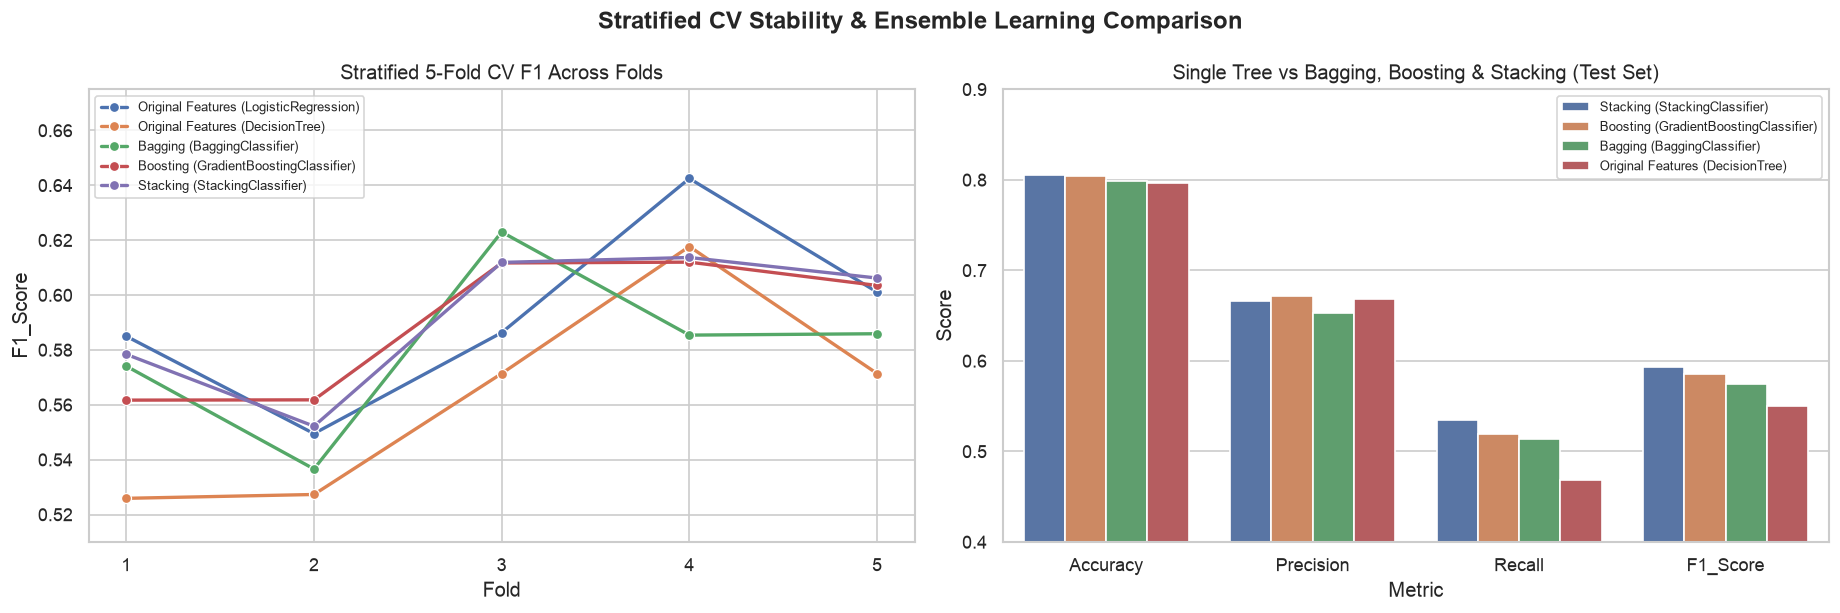

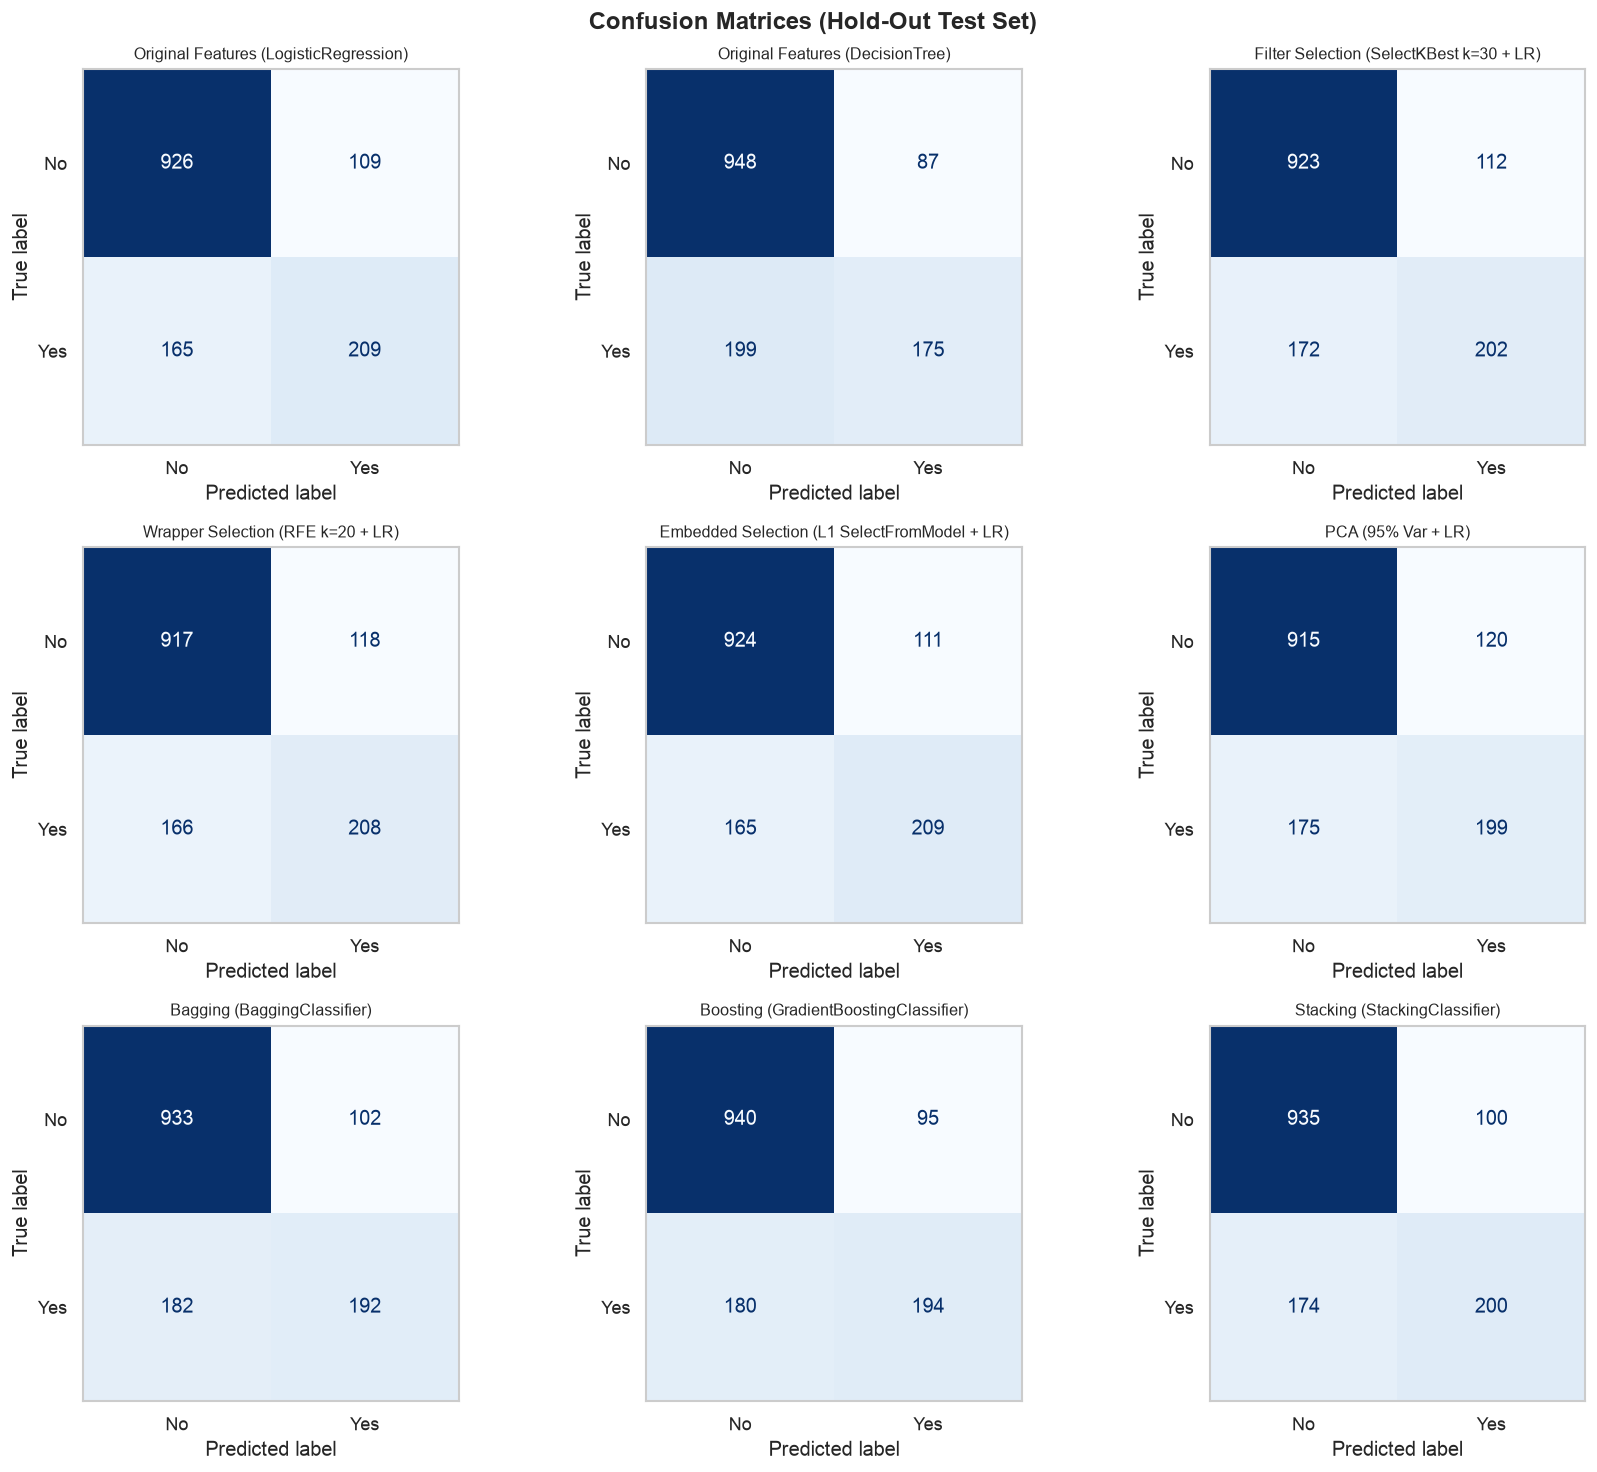

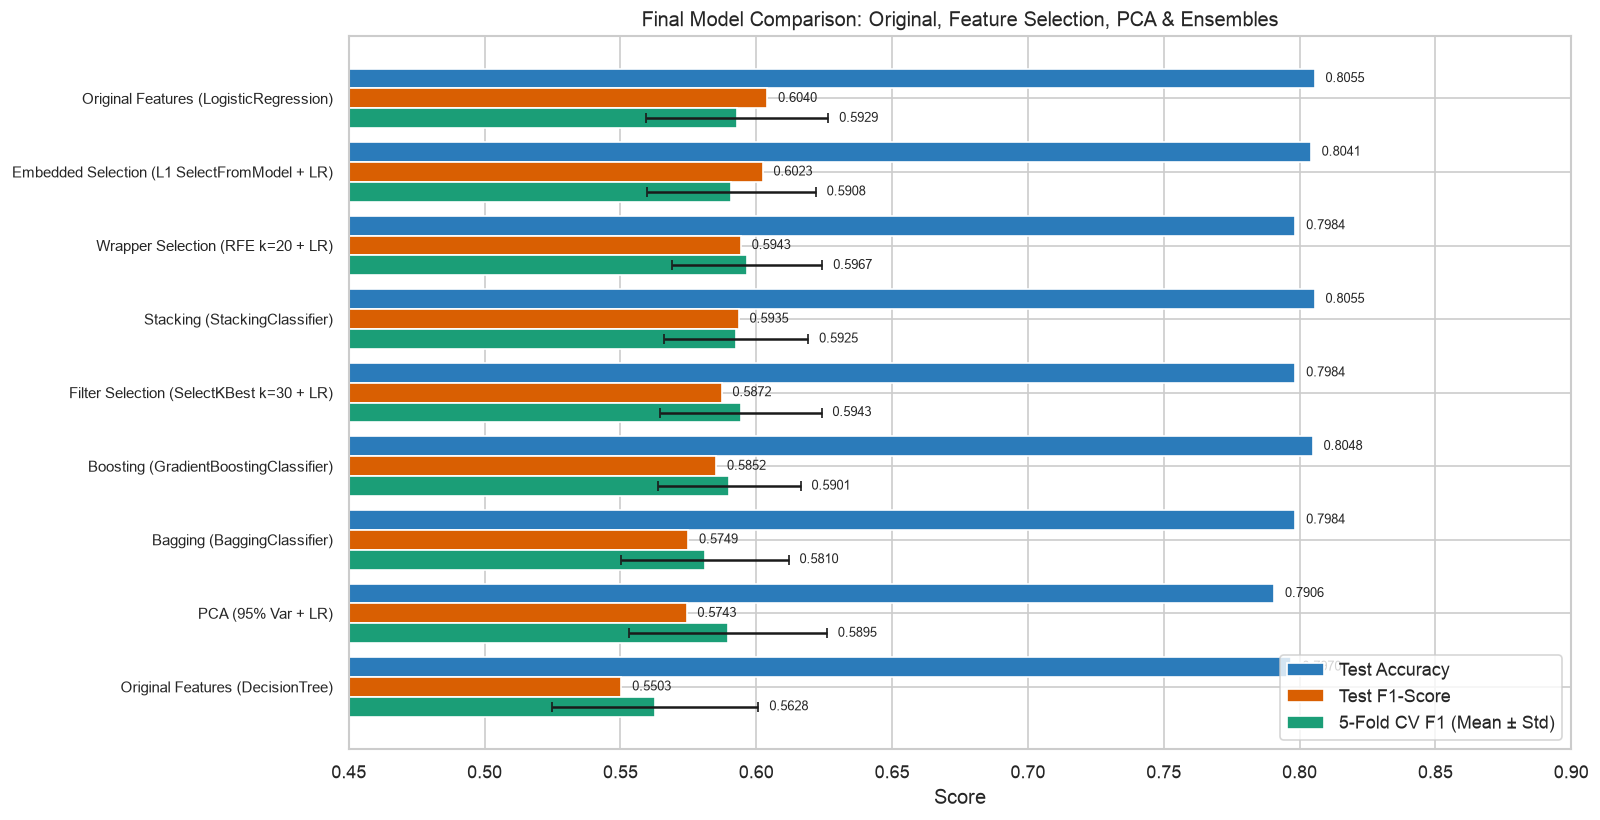

In [ ]:
# Plot 1: Stratified 5-Fold F1 Stability & Single Tree vs Ensembles Comparison
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

key_fold_models = [
    "Original Features (LogisticRegression)",
    "Original Features (DecisionTree)",
    "Bagging (BaggingClassifier)",
    "Boosting (GradientBoostingClassifier)",
    "Stacking (StackingClassifier)",
]
fold_plot_df = fold_detail_df[fold_detail_df["Model"].isin(key_fold_models)].melt(
    id_vars="Model", value_vars=[f"Fold_{i}_F1" for i in range(1, 6)],
    var_name="Fold", value_name="F1_Score"
)
fold_plot_df["Fold"] = fold_plot_df["Fold"].str.extract(r"(\d+)").astype(int)
sns.lineplot(data=fold_plot_df, x="Fold", y="F1_Score", hue="Model", marker="o", linewidth=2, ax=axes[0])
axes[0].set_title("Stratified 5-Fold CV F1 Across Folds")
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_ylim(0.51, 0.675)
axes[0].legend(fontsize=8, loc="upper left")

ens_models = ["Original Features (DecisionTree)", "Bagging (BaggingClassifier)",
              "Boosting (GradientBoostingClassifier)", "Stacking (StackingClassifier)"]
ens_plot_df = comparison_df[comparison_df["Model"].isin(ens_models)].melt(
    id_vars="Model", value_vars=["Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1_Score"],
    var_name="Metric", value_name="Score"
)
ens_plot_df["Metric"] = ens_plot_df["Metric"].str.replace("Test_", "")
sns.barplot(data=ens_plot_df, x="Metric", y="Score", hue="Model", ax=axes[1])
axes[1].set_title("Single Tree vs Bagging, Boosting & Stacking (Test Set)")
axes[1].set_ylim(0.40, 0.90)
axes[1].legend(fontsize=8, loc="upper right")

plt.suptitle("Stratified CV Stability & Ensemble Learning Comparison", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "14_stratified_kfold_and_ensembles.png"), dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: Confusion Matrices using Scikit-learn ConfusionMatrixDisplay
fig, axes = plt.subplots(3, 3, figsize=(14.5, 12.5))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=label_encoder.classes_,
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name, fontsize=9.5)
    ax.grid(False)

plt.suptitle("Confusion Matrices (Hold-Out Test Set)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "15_confusion_matrices.png"), dpi=200, bbox_inches="tight")
plt.show()

# Plot 3: Final Comprehensive Bar Chart
ordered = comparison_df.sort_values("Test_F1_Score", ascending=True).reset_index(drop=True)
y_pos = np.arange(len(ordered))
h = 0.27

fig, ax = plt.subplots(figsize=(13.5, 7))
ax.barh(y_pos + h, ordered["Test_Accuracy"], height=h, color="#2b7bba", label="Test Accuracy")
ax.barh(y_pos, ordered["Test_F1_Score"], height=h, color="#d95f02", label="Test F1-Score")
ax.barh(y_pos - h, ordered["CV_F1_Mean"], xerr=ordered["CV_F1_Std"], height=h, color="#1b9e77", capsize=3, label="5-Fold CV F1 (Mean ± Std)")

for i, row in ordered.iterrows():
    ax.text(row["Test_Accuracy"] + 0.004, i + h, f"{row['Test_Accuracy']:.4f}", va="center", fontsize=8)
    ax.text(row["Test_F1_Score"] + 0.004, i, f"{row['Test_F1_Score']:.4f}", va="center", fontsize=8)
    ax.text(row["CV_F1_Mean"] + row["CV_F1_Std"] + 0.004, i - h, f"{row['CV_F1_Mean']:.4f}", va="center", fontsize=8)

ax.set_yticks(y_pos)
ax.set_yticklabels(ordered["Model"], fontsize=9)
ax.set_xlim(0.45, 0.90)
ax.set_xlabel("Score")
ax.set_title("Final Model Comparison: Original, Feature Selection, PCA & Ensembles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, "16_final_model_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Print detailed Scikit-learn Classification Reports for representative models
for m_name in [
    "Original Features (LogisticRegression)",
    f"Wrapper Selection (RFE k={best_rfe_k} + LR)",
    "PCA (95% Var + LR)",
    "Bagging (BaggingClassifier)",
    "Boosting (GradientBoostingClassifier)",
    "Stacking (StackingClassifier)",
]:
    print("=" * 65)
    print(f"Classification Report: {m_name}")
    print(reports[m_name])

Classification Report: Original Features (LogisticRegression)
              precision    recall  f1-score   support

          No     0.8488    0.8947    0.8711      1035
         Yes     0.6572    0.5588    0.6040       374

    accuracy                         0.8055      1409
   macro avg     0.7530    0.7268    0.7376      1409
weighted avg     0.7979    0.8055    0.8002      1409

Classification Report: Wrapper Selection (RFE k=20 + LR)
              precision    recall  f1-score   support

          No     0.8467    0.8860    0.8659      1035
         Yes     0.6380    0.5561    0.5943       374

    accuracy                         0.7984      1409
   macro avg     0.7424    0.7211    0.7301      1409
weighted avg     0.7913    0.7984    0.7938      1409

Classification Report: PCA (95% Var + LR)
              precision    recall  f1-score   support

          No     0.8394    0.8841    0.8612      1035
         Yes     0.6238    0.5321    0.5743       374

    accuracy         

## Conclusion, Limitations & Future Scope

- **Best Models:**
  - **Highest Hold-out Test F1 (`0.6040`) & Tied Highest Test Accuracy (`0.8055`):** `Original Features (LogisticRegression)` — confirming strong additive linear signal across contract type, tenure, internet service, and billing mode.
  - **Highest 5-Fold Stratified CV Accuracy (`0.8067 ± 0.0127`) & Tied Highest Test Accuracy (`0.8055`):** `StackingClassifier` — fusing linear, Bagging, and Gradient Boosting predictions improves cross-validated generalization and lowers F1 variance (`±0.0266`).
  - **Highest 5-Fold Stratified CV F1 (`0.5967 ± 0.0276`):** `Wrapper Selection (RFE k=20 + LR)` — removes 50% of encoded features while matching or exceeding full-feature CV F1.
  - **Ensemble Gain Over Single Tree:** Both `BaggingClassifier` (`0.5749` Test F1) and `GradientBoostingClassifier` (`0.5852` Test F1, highest Test Precision `0.6713`) clearly outperform the single `DecisionTreeClassifier` (`0.5503` Test F1).
- **Limitations:** Class imbalance (`26.54%` churn) keeps Recall around `47%–56%` at the default `0.50` threshold; static customer snapshot data lacks temporal usage history; high-dimensional one-hot features make DBSCAN sensitive to `eps`.
- **Future Scope:** Tune classification probability thresholds using Precision-Recall trade-offs aligned with retention campaign ROI, experiment with `class_weight='balanced'`, and add time-series usage features if collected.